# ODE Modelling Conjugation in a Community
*Written by: An Mei Daniels (anmei.daniels@linacre.ox.ac.uk), Stracy Lab*

The experiment we are working on is to determine the effect of various drugs on the gut microbiome, which then may enable or prevent the spread on antibiotic resistance genes (ARG). The current theory is that if drugs successfully peturb the microbiome, the allows the overgrowth of donors and potential recipients, increasing the odds they would come in contact with each other to allow conjugation to occur. We also want to understand the influence of spatial structure within the gut - where different species are localised in the gut microbiome - on this phenomenon. While we are currently conduction *in vitro* and *in vivo* mouse experiments, we would also like to develop a model which explores the dynamics of this.

There are multiple different modelling approaches for studying the microbiome ([Kumar, 2019](https://www.nature.com/articles/s41564-019-0491-9#Sec11)). The two most relevant methods are ordinary differential equation (ODEs)-based modelling, and agent-based modelling (ABMs). Here we will focus on ODE-based modelling. ODE-based modelling has been used to model monocultures or simple co-culture systems (minimal species), using rate equations to measure the change in different variables in time - such as species growth or plasmid transfer. The rate equations can be used to create mass balances (a set of ODEs that can be solved using standard computational solvers). These ODEs allows the simulation of dynamic interactions between species, but they often have to be simplified to reduce the number of variables and parameters.

In [1]:
# General modules
import os  # noqa: I001
import numpy as np
import numpy.random as rd
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
filepath = os.path.abspath("")
datadir = f'{filepath}/data/'
figdir = f'{filepath}/figures/'

## [Generalised Lotka-Volterra, gLV (1987)](https://stefanoallesina.github.io/ICTS_2025/ch1.html)

LV models are widely used to describe the time evolution of ecosystems, often in a classical predator-prey LV model (where two competing populations directly affect each other's growth, either positively or negatively) ([Succurro, 2018](https://pmc.ncbi.nlm.nih.gov/articles/PMC5906705/#s2)). Model parameters, including initial conditions, quantify direct interactions to determine the stability of the system and can be numerically solved. [Gavina *et al.* (2019)](https://www.nature.com/articles/s41598-017-19044-9) incorporated the crowding effect $m$ into a LV model, to add an addition term to further reduce growth in populations with high density, which can better account for bacterial growth in a closed system. [Stein *et al.* (2013)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3861043/#s4) implemented an expansion of the gLV model, which includes a term to model susceptibility, $\epsilon$, to an external perturbation such as a drug $p(t)$.

To construct this programme, we used code from Laura de Nies (Stracy lab), in combination with information from Coyte's papers:
- [The ecology of the microbiome: Networks, competition, and stability (2015)](https://www.science.org/doi/full/10.1126/science.aad2602#abstract)
- [Horizontal gene transfer and ecological interactions jointly control microbiome stability (2022)](https://journals.plos.org/plosbiology/article?id=10.1371/journal.pbio.3001847#sec008)

The equation used here to model growth is:
$$
\frac{dx_i(t)}{dt} = x_i(t) \left(r_i \sum_j \alpha_{ij}x_j(t) - m_i + \epsilon_i p(t) \right) + \gamma
$$ 
where:
- $\frac{dx_i(t)}{dt}$ is the change in population density for species $i$ between time $t$ and $t+1$
- $x_i(t)$ is the population densities of species $i$ at time $t$
- $r_i$ is the intrinsic growth rates (or death rates when negative) measuring the growth/decline of population $i$ when growing alone at low density
- $\mathbf{\alpha}$ is an $n \times n $ matrix of interaction coefficients, with self-inhibition (or growth) vector $\mathbf{s}(x)$ as the diagonal matrix
- $m_i$ is the crowding effect rate for species $i$
- $\epsilon_i$ is the susceptibility of species $i$ to the perturbation (in this case the antibiotic)
- $p$ is the overall strength of the perturbation introduced
- $\gamma$ is the term considering plasmid transfer, and how that affects the population (ie. changing some cells from recipients to transconjugants)

The class to run this model is imported from below:

In [2]:
from ode_model import ode_lotka
np.random.seed(42)

This notebook is used to walk you through what parameters make up the model and identify their impact on the number of transconjugants formed.

## Determining Species Number

 The model is initialised for a run using `ode_lotka(n_species)`.The parameter `n_species` is used to determine the number of species in the community, excluding the donor, recipient and transconjugants. Therefore, a value of `n_species = 1` would have 4 species total. The number of species determines how many linked ODE equations need to be solved, with the number of entries in $x(t)$ and the size of the interaction matrix.

In this model, the recipient species and the transconjugant species are treated as the same - namely, they have the same interactions with other species. As a default, the donor is also the same species as the recipient and transconjugant, with the same interactions as both. However, there is an option to set the donor and recipient to be different species with different interactions. Either way, the donor, recipient and transconjugants can have different suceptibilities to the drug to model the effect of receiving resistance genes from conjugative plasmids.

The starting species density `x0` is a parameter entered as an array with `3 + n_species` entries. Species (including donor and recipient when 'spiked in') are likely not to remain at the starting density, as the system will always try to tend to equilibrium based on the ODEs. This may not reflect real experimental behaviour, where species may remain in stationary phase at the OD they are introduced at.

#### The Crowding Effect
This model also incorporates a term for the crowding effect, which incorporates competition for resources in a closed system, not just the direct interaction effects of species upon each other.

$$m_i = m_{0} + d x_i^\delta, \delta\in(0,\infty)$$
where
- $m_0$ is the initial mortality of the species (if $m_0=0$ then intraspecific competition is 100% density-dependent), given in this model as $0.001$
- $d$ is the density-dependent factor, given as $0.01$
- note that $0 < m_0 + d \geq 1$
- $\delta$ is the strength of the effect of the population density, given as $1$

The crowding effect inhibits the growth of species in the population if the population densities are very high, another factor providing inhibition to population growth in addition to negative interactions between species. This can more closely mimic community growth in a closed system, to further limit carrying capacity. The model allows you to turn this effect off, which you can do in the overall `Run Model` tab, but is generally kept on to more closely follow real-world effects.

However, as the number of species in an unperturbed community increases, the number of transconjugants decreases as the other species suppress the growth of the donor and recipient, decreasing the chances that conjugation may occur.

In [3]:
# PARAMETERS

# Number of species to use
n_species = np.linspace(0, 26, 27)                # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                  # community connectivty (probability of interactions)
sigma = 0.04                                      # interspecies interaction strength standard deviation
P_m = 0                                           # proportion of species reactions that are positive
self_inhibition = 0.1                             # intra-specific interaction strength
intrinsic_growth = 1                              # instrinsic growth rate

# Parameters for the model
conjugation_rate = 5e-4                           # average plasmid conjugation rate
drug_level = 0                                    # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                       # starting timestep
t_end = 300                                       # ending timestep

In [4]:
# Initialise model
repeat = 30
final_transconjugants = np.zeros([len(n_species), repeat])  # array to save data in

for r in range(repeat):
    print(f'Repeat {r+1}')
    susceptibility = [0, 0, 0]  # susceptibility of susceptible taxa
    x0 = [5e-5, 5e-5, 0]  # starting population size
    for s in range(len(n_species)):
        vary_nspecies = ode_lotka(int(n_species[s]))  # initialise model
        if s == 0: 
            vary_nspecies.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
            alpha = vary_nspecies.alpha
        # Update parameters
        else:
            x0.append(1)
            susceptibility.append(0.5)
            vary_nspecies.good_alpha = 0
            while vary_nspecies.good_alpha == 0:
                col = np.array(sigma * abs(rd.randn(int(n_species[s])+2)) * -1).reshape(-1,1)
                row = np.array(sigma * abs(rd.randn(int(n_species[s])+3)) * -1)
                new_alpha = np.hstack([alpha, col])
                new_alpha = np.vstack([new_alpha, row])
                vary_nspecies.enter_custom_interaction_matrix(new_alpha, self_inhibition=self_inhibition)  # initialise interaction matrix
        alpha = vary_nspecies.alpha
        # Run model
        vary_nspecies.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
        final_transconjugants[s][r] = vary_nspecies.results.y[2, -1]  # final number of transconjugants
np.save(f'{datadir}change_nspecies', final_transconjugants)

Repeat 1
Repeat 2
Repeat 3
Repeat 4
Repeat 5
Repeat 6
Repeat 7
Repeat 8
Repeat 9
Repeat 10
Repeat 11
Repeat 12
Repeat 13
Repeat 14
Repeat 15
Repeat 16
Repeat 17
Repeat 18
Repeat 19
Repeat 20
Repeat 21
Repeat 22
Repeat 23
Repeat 24
Repeat 25
Repeat 26
Repeat 27
Repeat 28
Repeat 29
Repeat 30


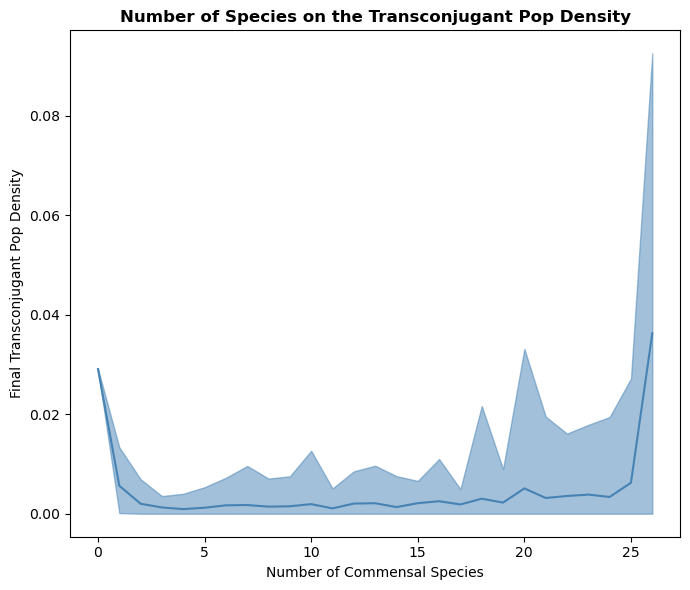

In [5]:
#Load data
n_species = np.linspace(0, 26, 27)
final_transconjugants = np.load(f'{datadir}/change_nspecies.npy')
 
# Plot the results of the effect of conjugation_rate on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
plt.plot(n_species, final_transconjugants.mean(axis=1), color='steelblue')
plt.fill_between(n_species, np.percentile(final_transconjugants, 5, axis=1), np.percentile(final_transconjugants, 95, axis=1), alpha=0.5, color='steelblue')
ax.set_xlabel('Number of Commensal Species')
ax.set_ylabel('Final Transconjugant Pop Density')
plt.title('Number of Species on the Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_nspecies_transconjugants.png', dpi=500)
plt.show()

## Building the Interaction Matrix

To build the interaction matrix alpha, $\alpha_{ij}$, we used parameters to determine how the matrix was randomly populated. The matrix can be completely randomly populated based on the parameters using the `randomise_interaction_matrix(*parameters)` function.

The matrix can also be entered manually using two different functions. `enter_custom_interaction_matrix(*parameters)` will make some corrections, such as ensuring the transconjugants have the same parameters as the recipients, ensuring the diagonal has the same self-inhibition rates as entered, and will calculate the growth rate and stability from the values entered. There is also `set_interaction_matrix(alpha, intrinsic_growth)` function which lets you set the interaction matrix and growth rate from entered values and automatically assumes the values are good. This walkthrough does not interact with either of those functions, as that can lead to an unsolvable ODE equation. If you want to be able to play with these functions, you can write your own.

To determine if the ODEs can be solved and the system reaches equilibrium with the randomly generated interaction matrix, the Jacobian is calculated and its eigenvalues are found. The interaction matrix and growth rates calculated and used can be displayed using `display_matrix_used()`. For reproducibility, the interaction matrix and growth rates can be saved to .csv files using `save_interaction_matrix_r()`, which can then be reloaded, using `upload_interaction_matrix_r()`.

Some of the parameters used when randomising the matrix are:

### Connectivity
$C\in[0,1]$ `connectivity`: the connectivity between different species in the community, the fraction of all `n_species` species that a single species interacts with 
- this is set to $0$ if there is no interaction for different species and a values are set to $0$
- if there is an interaction between them, a proportion of entries equal to $C$ in $\alpha_{ij}$ are given values not equal to $0$

Below, a lower connectivity means all species can grow to saturation. While that includes the donor and recipient, the high population densities of other species in the community prevents contact from occuring between the donor and recipient that is necessary for conjugation to occur. 

In [6]:
# PARAMETERS

# Number of species to use
n_species = 5                                    # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = np.linspace(0, 1, 51)              # community connectivty (probability of interactions)
sigma = 0.15                                      # interspecies interaction strength standard deviation
P_m = 0                                           # proportion of species reactions that are positive
self_inhibition = 0.1                             # intra-specific interaction strength
intrinsic_growth = 1                              # instrinsic growth rate

# Parameters for the model
conjugation_rate = 5e-4                           # average plasmid conjugation rate
susceptibility = np.zeros(3 + n_species)          # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                                    # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                       # starting timestep
t_end = 300                                       # ending timestep
x0 = [5e-5, 5e-5, 0] + [1] * n_species            # starting population size

In [7]:
# Initialise model
vary_connectivity = ode_lotka(n_species)  # initialise model
repeat = 30

final_transconjugants = np.zeros([len(connectivity), repeat])  # array to save data in
for r in range(repeat):
    print(f'Repeat {r+1}')
    # Try different conjugation_rate values
    for s in range(len(connectivity)):  # loop through recipient susceptibilities
        # For initial susceptibility
        if s == 0: 
            vary_connectivity.randomise_interaction_matrix(connectivity[s], sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
            alpha = vary_connectivity.alpha; old_interactions = 0  # define old parameters
            # Get initial indices
            indices = np.indices((8,8)).transpose((1,2,0))
            indices = np.concat([indices[3:,3:].reshape(25,2), indices[0,3:], indices[3:,0]])
            indices = [tuple(val.tolist()) for val in indices if val[0] != val[1]]
            # Check the actual connectivity of matrix
            non_self = vary_connectivity.alpha[vary_connectivity.alpha!=-0.1]
            filled = non_self[non_self!=0].size
        else:
            vary_connectivity.good_alpha = 0
            # Get random connectivity to figure out how many values to fill
            C = rd.uniform(size=(5,10)) 
            interactions = len(C[C > (1-connectivity[s])])
            interactions = max(interactions - old_interactions, 0)
            if filled / non_self.size >= connectivity[s]: interactions = 0
            # Try to fill in values and make sure matrix is solvable
            while vary_connectivity.good_alpha == 0:
                # New matrix to try and get values
                new_alpha = alpha.copy()
                new_indices = indices.copy()
                vals = (sigma * abs(rd.randn(interactions))) * -1
                # For each value, try a coordinate with it and a value
                for i in range(interactions):
                    rd.shuffle(new_indices); coords = new_indices.pop()
                    new_alpha[coords[0],coords[1]] = vals[i]
                # Check to make sure it is solvable
                vary_connectivity.enter_custom_interaction_matrix(new_alpha, self_inhibition=self_inhibition)  # initialise interaction matrix
        # Check the actual connectivity of matrix
        alpha = vary_connectivity.alpha
        non_self = vary_connectivity.alpha[vary_connectivity.alpha!=-0.1]
        old_interactions = filled = non_self[non_self!=0].size
        vary_connectivity.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
        final_transconjugants[s][r] = vary_connectivity.results.y[2, -1]  # final number of transconjugants
np.save(f'{datadir}/change_connectivity', final_transconjugants)

Repeat 1
Repeat 2
Repeat 3
Repeat 4
Repeat 5
Repeat 6
Repeat 7
Repeat 8
Repeat 9
Repeat 10
Repeat 11
Repeat 12
Repeat 13
Repeat 14
Repeat 15
Repeat 16
Repeat 17
Repeat 18
Repeat 19
Repeat 20
Repeat 21
Repeat 22
Repeat 23
Repeat 24
Repeat 25
Repeat 26
Repeat 27
Repeat 28
Repeat 29
Repeat 30


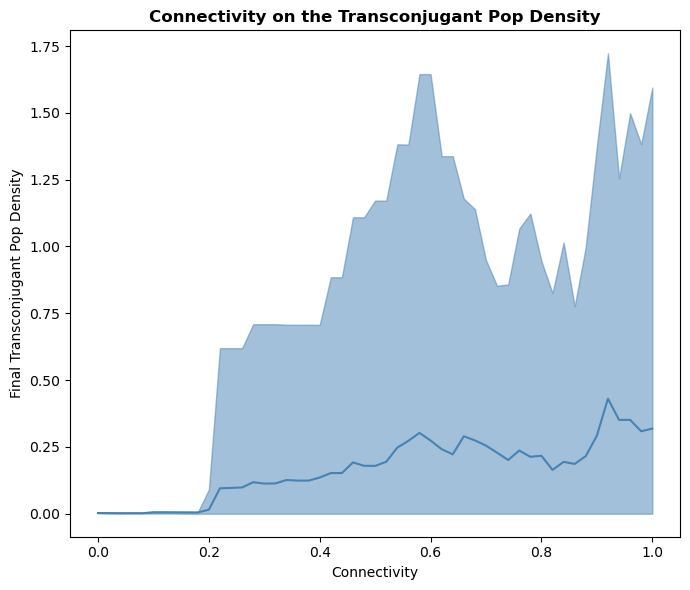

In [8]:
#Load data
connectivity = np.linspace(0, 1, 51) 
final_transconjugants = np.load(f'{datadir}/change_connectivity.npy')
 
# Plot the results of the effect of conjugation_rate on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
plt.plot(connectivity, final_transconjugants.mean(axis=1), color='steelblue')
plt.fill_between(connectivity, np.percentile(final_transconjugants, 5, axis=1), np.percentile(final_transconjugants, 95, axis=1), alpha=0.5, color='steelblue')
ax.set_xlabel('Connectivity')
ax.set_ylabel('Final Transconjugant Pop Density')
plt.title('Connectivity on the Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_connectivity_transconjugants.png', dpi=500)
plt.show()

### Self-Inhibition and Strength of Interactions

$\sigma$ `sigma`: the standard deviation of the normal distribution that the strength of the interactions between species is drawn from
- the actual value of $\alpha_{ij}$ given a value between -1 and +1

$s_i$ `self_inhibition`: the self inhibition rate of species $i$, or effect of a species on itself (we assume each species competes to the same extent with members of their own species)
- diagonal entries in the interaction matrix will be set to have the value $−\mathbf{s}$

donors, recipients, and transconjugant parameters
- between the recipients and transconjugants (and typically the donor), the interaction strength will be set to be the same for all entries
- additionally the interaction matrix entries between the recipient and transconjugant (and typically the donor) will be the same as the self-inhibition value

The following loop determines the effect of different `sigma` values on the actual outputs in the interaction matrix, ignoring the `self_inhibition` value.

In [9]:
# PARAMETERS FOR NEGATIVE INTERACTION STRENGTH
n_species = 1                                         # number of different species in the community (in addition to donor and recipient)
connectivity = 1                                      # community connectivty (probability of interactions)
sigma = np.linspace(0, 1.5, int(1.5/0.01)+1)          # VARYING: interspecies interaction strength standard deviation
P_m = 0                                               # proportion of species reactions that are positive
self_inhibition = 0.1                                 # intra-specific interaction strength
intrinsic_growth = 1                                  # instrinsic growth rate
conjugation_rate = 5e-4                               # average plasmid conjugation rate
susceptibility = np.zeros(3 + n_species)              # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                                        # magnitude of perturbation, between 0 and 1
t_start = 0                                           # starting timestep
t_end = 300                                          # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                 # starting population size

# Initialise model
interaction_strength_negative = ode_lotka(n_species)  # initialise model

# Try different sigma values
repeat = 30
alpha_mean_negative = np.zeros([len(sigma), repeat])
final_change_x_negative = np.zeros([len(sigma), repeat, 4])  # array to save final change in growth from starting value
for r in range(repeat):
    print(f'Starting repeat {r+1}.')
    for s in range(len(sigma)):  # loop through recipient susceptibilities
        interaction_strength_negative.randomise_interaction_matrix(connectivity, sigma[s], P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
        alpha_mean_negative[s][r] = interaction_strength_negative.alpha[interaction_strength_negative.alpha != -self_inhibition].mean()
        interaction_strength_negative.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
        final_change_x_negative[s][r] = interaction_strength_negative.results.y[:, -1] - x0
np.save(f'{datadir}change_negative_sigma_alpha', alpha_mean_negative)
np.save(f'{datadir}change_negative_sigma_finalx', final_change_x_negative)

Starting repeat 1.
Starting repeat 2.
Starting repeat 3.
Starting repeat 4.
Starting repeat 5.
Starting repeat 6.
Starting repeat 7.
Starting repeat 8.
Starting repeat 9.
Starting repeat 10.
Starting repeat 11.
Starting repeat 12.
Starting repeat 13.
Starting repeat 14.
Starting repeat 15.
Starting repeat 16.
Starting repeat 17.
Starting repeat 18.
Starting repeat 19.
Starting repeat 20.
Starting repeat 21.
Starting repeat 22.
Starting repeat 23.
Starting repeat 24.
Starting repeat 25.
Starting repeat 26.
Starting repeat 27.
Starting repeat 28.
Starting repeat 29.
Starting repeat 30.


In [10]:
# ADJUSTING PARAMETERS FOR positive INTERACTIONS
P_m = 1                                              # proportion of species reactions that are positive

# Initialise model
interaction_strength_positive = ode_lotka(n_species)  # initialise model

# Try different sigma values
repeat = 30
alpha_mean_positive = np.zeros([len(sigma), repeat])
final_change_x_positive = np.zeros([len(sigma), repeat, 4])  # array to save final change in growth from starting value
for r in range(repeat):
    print(f'Starting repeat {r+1}.')
    for s in range(len(sigma)):  # loop through recipient susceptibilities
        interaction_strength_positive.randomise_interaction_matrix(connectivity, sigma[s], P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
        alpha_mean_positive[s][r] = interaction_strength_positive.alpha[interaction_strength_positive.alpha != -self_inhibition].mean()
        interaction_strength_positive.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
        final_change_x_positive[s][r] = interaction_strength_positive.results.y[:, -1] - x0  # final change
np.save(f'{datadir}change_positive_sigma_alpha', alpha_mean_positive)
np.save(f'{datadir}change_positive_sigma_finalx', final_change_x_positive)

Starting repeat 1.
Starting repeat 2.
Starting repeat 3.
Starting repeat 4.
Starting repeat 5.
Starting repeat 6.
Starting repeat 7.
Starting repeat 8.
Starting repeat 9.
Starting repeat 10.
Starting repeat 11.
Starting repeat 12.
Starting repeat 13.
Starting repeat 14.
Starting repeat 15.
Starting repeat 16.
Starting repeat 17.
Starting repeat 18.
Starting repeat 19.
Starting repeat 20.
Starting repeat 21.
Starting repeat 22.
Starting repeat 23.
Starting repeat 24.
Starting repeat 25.
Starting repeat 26.
Starting repeat 27.
Starting repeat 28.
Starting repeat 29.
Starting repeat 30.


In [11]:
# Get the final merged values of positive and negative values
sigma = np.linspace(0, 1.5, int(1.5/0.01)+1)
alpha_mean_negative = np.load(f'{datadir}change_negative_sigma_alpha.npy')
final_change_x_negative = np.load(f'{datadir}change_negative_sigma_finalx.npy')
alpha_mean_positive = np.load(f'{datadir}change_positive_sigma_alpha.npy')
final_change_x_positive = np.load(f'{datadir}change_positive_sigma_finalx.npy')
final_change_x_mean = np.concat([final_change_x_negative, final_change_x_positive])

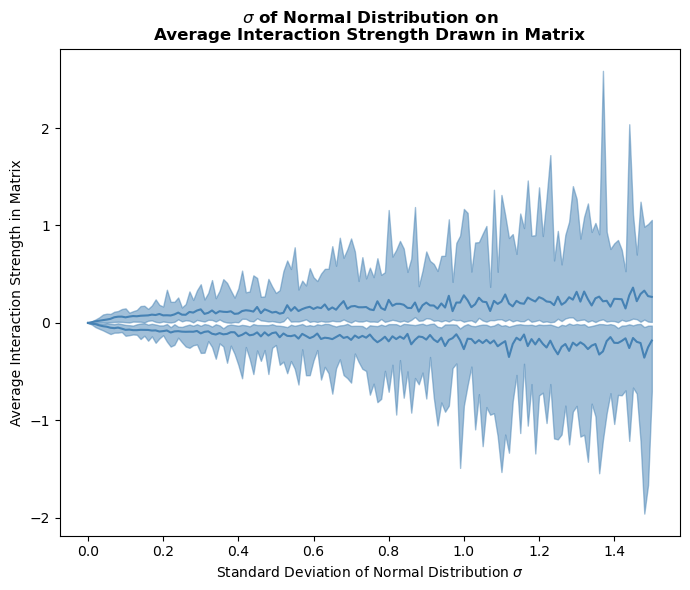

In [12]:
# Plot the results of the effect of the s.d. which interaction has been drawn on the average interaction strength in the matrix
fig, ax = plt.subplots(figsize=(7,6))
plt.plot(sigma, alpha_mean_negative.mean(axis=1), color='steelblue')
plt.fill_between(sigma, alpha_mean_negative.min(axis=1), alpha_mean_negative.max(axis=1), alpha=0.5, color='steelblue')
plt.plot(sigma, alpha_mean_positive.mean(axis=1), color='steelblue')
plt.fill_between(sigma, alpha_mean_positive.min(axis=1), alpha_mean_positive.max(axis=1), alpha=0.5, color='steelblue')
ax.set_xlabel(r'Standard Deviation of Normal Distribution $\sigma$')
ax.set_ylabel('Average Interaction Strength in Matrix')
plt.title(r'$\sigma$ of Normal Distribution on' '\nAverage Interaction Strength Drawn in Matrix', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_sigma_alpha.png', dpi=500)
plt.show()

### Proportion of Positive Interactions
$P_m$ `P_m`: proportion of interactions that are positive, for assigning negative and positive interactions
- $P_m=0$: community is purely competitive (all values are less than 0)
- $P_m=0.5$: community contains a mixture of all interaction types
- $P_m=1$: community is purely cooperative (all values are greater than 0)
- these are values taken from a mix of potential interaction types, which are summed up by the $\alpha_{ij}$ value
    - $P_e$ (+/-): exploitative
    - $P_c$ (-/-): competitive
    - $P_m$ (+/+): cooperation
    - $P_+$ (+/0): commensalism
    - $P_−$ (-/0): ammensalism
    - $P_0$ (0/0): zero interactions
    - where $P_e+P_c+P_m+P_++P_−=1$

From above, the resulting mean value in the interaction matrix for a range of positive and negative values are then plotted against the resulting number of transconjugants.

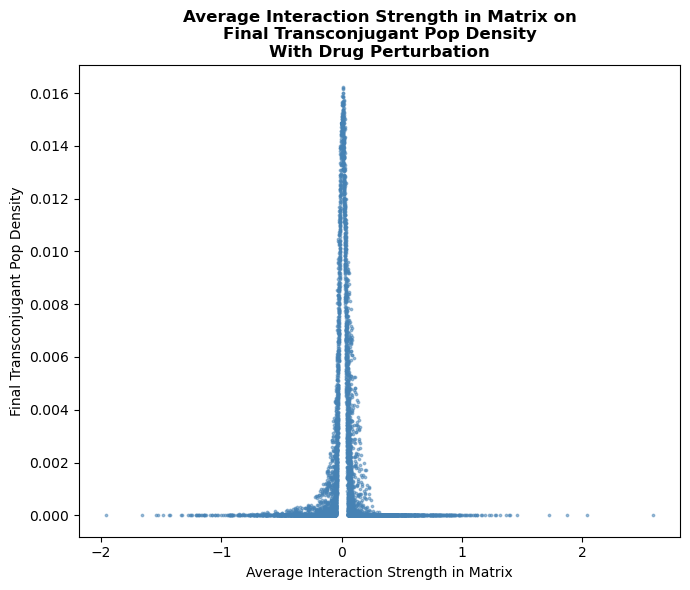

In [13]:
# Plot the results of the effect of the effect of the strength of interaction on the change in growth from x0
fig, ax = plt.subplots(figsize=(7,6))
plt.scatter(np.concat([alpha_mean_negative, alpha_mean_positive]), final_change_x_mean[:,:,2], label='transconjugants', color='steelblue', s=3, alpha=0.5)
ax.set_xlabel('Average Interaction Strength in Matrix')
ax.set_ylabel(r'Final Transconjugant Pop Density')
#ax.set_ylim(-0.05, 0.8)
plt.title('Average Interaction Strength in Matrix on\nFinal Transconjugant Pop Density\nWith Drug Perturbation', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_alpha_transconjugants.png', dpi=500)
plt.show()

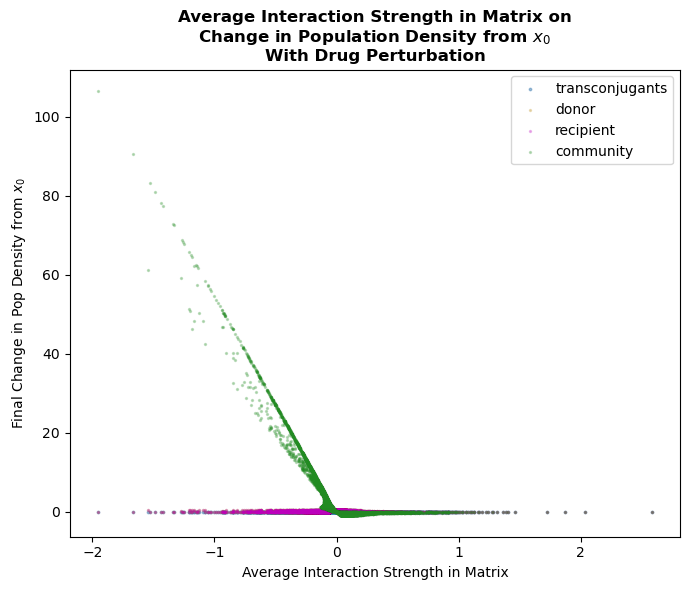

In [14]:
# Plot the results of the effect of the effect of the strength of interaction on the change in growth from x0
fig, ax = plt.subplots(figsize=(7,6))
plt.scatter(np.concat([alpha_mean_negative, alpha_mean_positive]), final_change_x_mean[:,:,2], label='transconjugants', color='steelblue', s=3, alpha=0.5)
plt.scatter(np.concat([alpha_mean_negative, alpha_mean_positive]), final_change_x_mean[:,:,0], label='donor', color='darkgoldenrod', s=2, alpha=0.25)
plt.scatter(np.concat([alpha_mean_negative, alpha_mean_positive]), final_change_x_mean[:,:,1], label='recipient', color='m', s=2, alpha=0.25)
plt.scatter(np.concat([alpha_mean_negative, alpha_mean_positive]), final_change_x_mean[:,:,3], label='community', color='forestgreen', s=2, alpha=0.25)
ax.set_xlabel('Average Interaction Strength in Matrix')
ax.set_ylabel(r'Final Change in Pop Density from $x_0$')
#ax.set_ylim(-1.5, 10)
plt.title('Average Interaction Strength in Matrix on\nChange ' r'in Population Density from $x_0$' ' \nWith Drug Perturbation', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.savefig(f'{figdir}vary_alpha_growth.png', dpi=500)
plt.show()

### Intrinsic Growth Rate

Once the interaction matrix and species self-interaction is defined, we can then identify the species growth rate, $r_i$:
- we assume the community has a linearly asymptotically stable equilibrium at $x_i \approx \text{intrinsic growth} \in i$, where the default value `intrinsic_growth = 1` $\pm$ some random noise
- intrinsic growth can also be an array provided with `3 + n_species`, so that each community species has their own growth rate
- the array `steady_state` is the length of the `3 + n_species`, with each of the values being around `intrinsic_growth`, with some random noise around the value
- note that even if different intrinsic growth rates are provided for donor/recipient/transconjugant species, as they have the same interaction matrix parameters, they will have the same calculated $r$ values
- $r$ is then found by a matrix multiplication of $\alpha$ and `steady_state`
- this introduces a trade-off in growth strategies, with species investing either in their own intrinsic growth rate or growth via cooperation with others, reducing unrealistic explosive behaviour in highly cooperative communities

In [15]:
# PARAMETERS

# Number of species to use
n_species = 1                                                        # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                                     # community connectivty (probability of interactions)
sigma = 0.6                                                          # interspecies interaction strength standard deviation
P_m = 0                                                              # proportion of species reactions that are positive
self_inhibition = 0.1                                                # intra-specific interaction strength
intrinsic_growth = 1                                                 # instrinsic growth rate

# Parameters to run the model
t_start = 0                                                          # starting timestep
t_end = 300                                                          # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                              # starting population size

# Parameters for conjugation
t_dr = 50                                                            # time that the donor and recipient are)
conjugation_rate = 5e-4                                              # average plasmid conjugation rate

# Parameters for the drug
susceptibility = np.zeros(3 + n_species)                             # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                                                       # magnitude of perturbation, between 0 and 1

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.01166537]
 [-0.1        -0.1        -0.1        -0.01166537]
 [-0.1        -0.1        -0.1        -0.01166537]
 [-0.33364963 -0.33364963 -0.33364963 -0.1       ]]

The growth rate is:
[0.11167253 0.11167171 0.11167735 1.10103362]



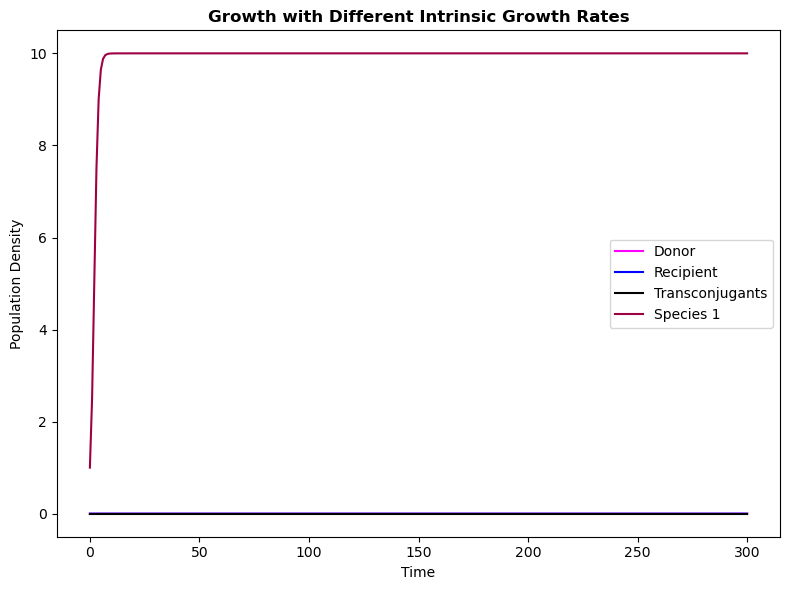

In [16]:
# Initialise model
test = ode_lotka(n_species)  # initialise model
test.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
test.display_matrix_used()
# Run model and plot the equilibrium and the general growth with simple conjugation that doesn't take into account population
test.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, t_dr=t_dr, equilibrium=False)  # solve ode
test.plot_results(test.results.t, test.results.y.T, 'Growth with Different Intrinsic Growth Rates', figsize=(8,6))

## Modelling Conjugation

The donor and recipient can be innoculated at `t_dr`, which can be a time later than `t = 0`. Both when optionally running with an equilibrium step - to let the community find equilibrium without any drug perturbations or pathogens - and when `t < t_dr`, the donor, recipient and transconjugant values are set to $0$. During this time, the `plasmid_transfer` term $\gamma=0$ which ensures that no transconjugation occurs. Afterwards, when `t > t_dr`, the population density for the community calculated by the ODE solver is carried forward, but the donor and recipient values are taken from the `x0` value inputted by the user.

To model conjugation, the system of equations includes a $\gamma$ term for only the recipient and transconjugant species. This float value `plasmid_transfer` is removed from the recipient population density, and is added to the transconjugant population density values. The final number in the transconjugant population is then used to measure the conjugation that has occurred. There are then two methods that can be used to determine plasmid transfer.

### Changing Donor and Recipient Time

This section demonstrates a model using a different time for adding the donor and recipient.

In [17]:
# PARAMETERS FOR CHANGING DR TIME

# Number of species to use
n_species = 1                               # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                            # community connectivty (probability of interactions)
sigma = 0.6                                 # interspecies interaction strength standard deviation
P_m = 0                                     # proportion of species reactions that are positive
self_inhibition = 0.1                       # intra-specific interaction strength
intrinsic_growth = 1                        # instrinsic growth rate

# Parameters at the start of the model
t_start = 0                                 # starting timestep
t_end = 300                                 # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                     # starting population size

# Parameters for conjugation
t_dr = 50                                   # time that the donor and recipient are added
conjugation_rate = 5e-4                     # average plasmid conjugation rate

# Parameters for the drug
susceptibility = np.zeros(4)                # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                              # magnitude of perturbation, between 0 and 1

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.02111261]
 [-0.1        -0.1        -0.1        -0.02111261]
 [-0.1        -0.1        -0.1        -0.02111261]
 [-0.05131075 -0.05131075 -0.05131075 -0.1       ]]

The growth rate is:
[0.12112104 0.12112433 0.12111052 0.25394231]



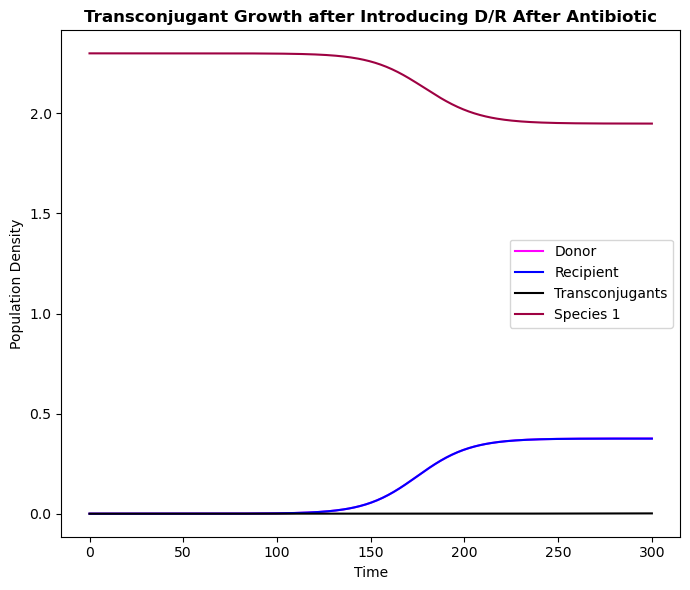

In [18]:
# Run model
vary_dr_time = ode_lotka(n_species)  # initialise model
vary_dr_time.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
vary_dr_time.display_matrix_used()

# Run the model with only introducing antibiotic at certain time
vary_dr_time.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, t_dr=t_dr)  # solve ODE
vary_dr_time.plot_results(vary_dr_time.results.t, vary_dr_time.results.y.T, 'Transconjugant Growth after Introducing D/R After Antibiotic')

### Simple Conjugation

The first method is `simple` method. The method takes `conjugation_rate` $\Gamma$ and determines the plasmid_transfer rate: 
$$\gamma=x_\text{recipients}[\Gamma(x_\text{donors}+x_\text{transconjugants})]$$

This therefore takes into account the number of donor and transconjugants that can donate the plasmid, and the number of recipients that could recieve it - accounting for physical number of donors which may limit the probability of coming into contact and donating the plasmid.

This graph compares the final transconjugant population density with varied conjugation rate.

In [19]:
# PARAMETERS

# Number of species to use
n_species = 1                                                        # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                                     # community connectivty (probability of interactions)
sigma = 0.6                                                          # interspecies interaction strength standard deviation
P_m = 0                                                              # proportion of species reactions that are positive
self_inhibition = 0.1                                                # intra-specific interaction strength
intrinsic_growth = 1                                                 # instrinsic growth rate

# Parameters for the model
conjugation_rate = np.logspace(-6, -1, 101, base=10)*5              # VARYING: average plasmid conjugation rate
susceptibility = np.zeros(4)                                        # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                                                      # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                                         # starting timestep
t_end = 300                                                         # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                             # starting population size

In [20]:
# Initialise model
conjugation_rate_model = ode_lotka(n_species)  # initialise model
repeat = 30

# Try different conjugation_rate values
final_transconjugants = np.zeros([len(conjugation_rate), repeat])  # array to save data in
for r in range(repeat):
    conjugation_rate_model.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
    print(f'Repeat {r+1}')
    for s in range(len(conjugation_rate)):  # loop through recipient susceptibilities
        conjugation_rate_model.solve_ode(t_start, t_end, x0, conjugation_rate[s], susceptibility, drug_level, plasmid_method='simple')  # solve ode
        final_transconjugants[s][r] = conjugation_rate_model.results.y[2, -1]  # final number of transconjugants
np.save(f'{datadir}change_conjugation_rate', final_transconjugants)

Repeat 1
Repeat 2
Repeat 3
Repeat 4
Repeat 5
Repeat 6
Repeat 7
Repeat 8
Repeat 9
Repeat 10
Repeat 11
Repeat 12
Repeat 13
Repeat 14
Repeat 15
Repeat 16
Repeat 17
Repeat 18
Repeat 19
Repeat 20
Repeat 21
Repeat 22
Repeat 23
Repeat 24
Repeat 25
Repeat 26
Repeat 27
Repeat 28
Repeat 29
Repeat 30


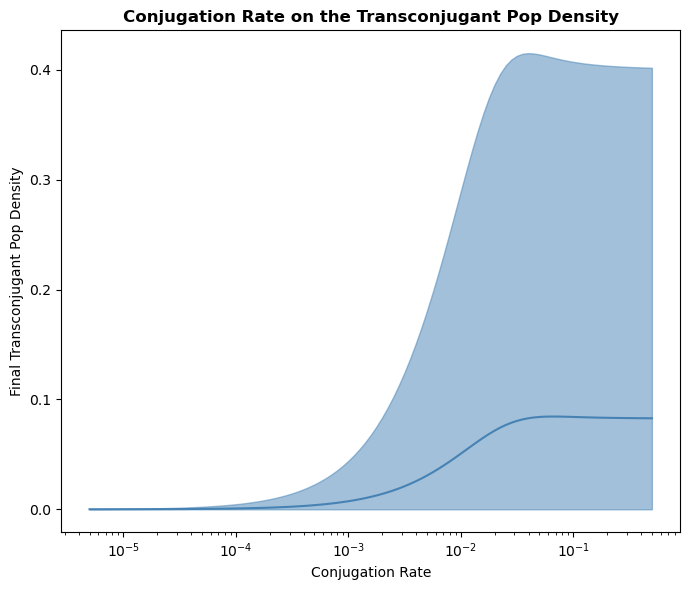

In [21]:
#Load data
conjugation_rate = np.logspace(-6, -1, 101, base=10)*5
final_transconjugants = np.load(f'{datadir}change_conjugation_rate.npy')

# Plot the results of the effect of conjugation_rate on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
plt.plot(conjugation_rate, final_transconjugants.mean(axis=1), color='steelblue')
plt.fill_between(conjugation_rate, np.percentile(final_transconjugants, 5, axis=1), np.percentile(final_transconjugants, 95, axis=1), alpha=0.5, color='steelblue')
ax.set_xlabel('Conjugation Rate')
ax.set_xscale('log')
ax.set_ylabel('Final Transconjugant Pop Density')
plt.title('Conjugation Rate on the Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_conjugationrate_transconjugants.png', dpi=500)
plt.show()

### Spatial Competition on Conjugation
The second and default method `proportion` also takes into account any other species in the community, and how they may spatially inhibit conjugation. Even if species don't have any interactions with the donor and recipient (set in the interaction matrix), they should still have an effect on conjugation rate due to the competition for space, and the limited ability for the donor to physically contact the recipient if there are high densities of other species in the way. The method takes `conjugation_rate` $\Gamma$ and determines the `plasmid_transfer` rate: 

$\gamma=x_\text{recipients}[\Gamma(x_\text{donors}+x_\text{transconjugants})]\times\rho\times\frac{1}{\lambda}$ where $\rho=\text{prop}_\text{donor + transconjugant} \times \text{prop}_\text{recpient}$

This method takes the simple `plasmid_transfer` rate and multiplies it by the proportion of cells in the population that can donate the plasmid and the proportion of cells in the population that can recieve the plasmid. Therefore, the more cells there are the community, the lower the proportion of donors and recipients, and the less likely they are to come into contact with each other for conjugation, even if there are high numbers of donor and recipient cells. This is similar to the crowding effect, implemented to influence plasmid transfer. This method is modulated by `prop_strength` $\lambda\in[0,1]$. The user entered value is corrected to prevent a divide by 0 error and take into account the strength of the effect, the number is then rescaled within the range $\lambda\in[\rho,1]$.

#### Varying Inhibition from Interaction Strength / Spatial Inhibition

In [22]:
# PARAMETERS

n_species = 1                                           # number of different species in the community (in addition to donor and recipient)
connectivity = 1                                        # community connectivty (probability of interactions)
sigma = np.linspace(0, 1.5, int(1.5/0.01)+1)            # interspecies interaction strength standard deviation
P_m = 0                                                 # proportion of species reactions that are positive
self_inhibition = 0.1                                   # intra-specific interaction strength
intrinsic_growth = 1                                    # approx steady state growth rate
conjugation_rate = 5e-4                                 # average plasmid conjugation rate
prop_strength = np.linspace(0, 1, 51)                   # strength of proportion interactions
susceptibility = np.zeros(4)                            # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                                          # magnitude of perturbation, between 0 and 1
t_start = 0                                             # starting timestep
t_end = 300                                             # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                 # starting population size

# Initialise model
vary_inhibition = ode_lotka(n_species)  # initialise model

In [23]:
repeat = 15
final_transconjugants = np.zeros([len(sigma), len(prop_strength), repeat])  # array to save data in

for r in range(repeat):
    print(f'Repeat {r+1}')
    for s in range(len(sigma)):  # loop through recipient susceptibilities
        vary_inhibition.randomise_interaction_matrix(connectivity, sigma[s], P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
        #vary_inhibition.display_matrix_used()
        for p in range(len(prop_strength)):
            vary_inhibition.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, plasmid_method='proportion', prop_strength=prop_strength[p])  # solve ode
            final_transconjugants[s][p][r] = vary_inhibition.results.y[2, -1]  # final number of transconjugants
np.save(f'{datadir}change_inhibition', final_transconjugants)

Repeat 1
Repeat 2
Repeat 3
Repeat 4
Repeat 5
Repeat 6
Repeat 7
Repeat 8
Repeat 9
Repeat 10
Repeat 11
Repeat 12
Repeat 13
Repeat 14
Repeat 15


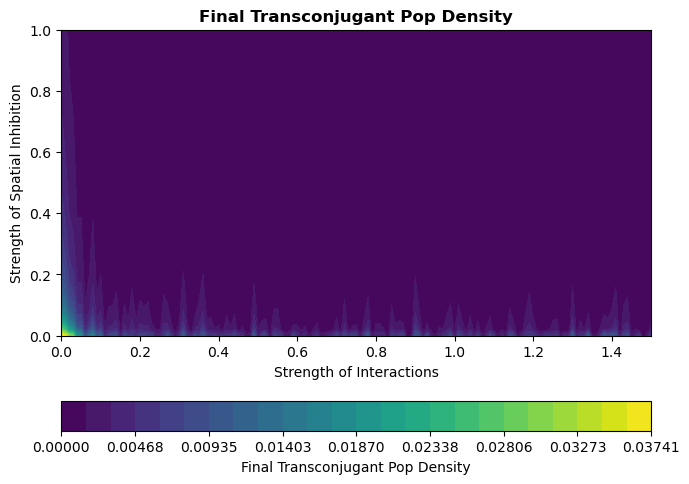

In [24]:
sigma = np.linspace(0, 1.5, int(1.5/0.01)+1)
prop_strength = np.linspace(0, 1, 51)
final_transconjugants = np.load(f'{datadir}change_inhibition.npy').mean(axis=2)

# Plot the results of the effect of susceptibility on transconjugants
fig, ax = plt.subplots(figsize=(7,5))
n_transconjugants = ax.contourf(sigma, prop_strength, final_transconjugants.T, cmap='viridis', levels=np.linspace(final_transconjugants.min(), final_transconjugants.max(), 25))
plt.colorbar(n_transconjugants, label='Final Transconjugant Pop Density', location='bottom', orientation='horizontal')
ax.set_xlabel('Strength of Interactions')
ax.set_ylabel('Strength of Spatial Inhibition')
plt.title('Final Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_inhibition.png', dpi=500)
plt.show()

#### Varying Conjugation Rate and Prop Strength

In [25]:
# PARAMETERS

n_species = 1                                           # number of different species in the community (in addition to donor and recipient)
connectivity = 1                                        # community connectivty (probability of interactions)
sigma = 0.6                                             # interspecies interaction strength standard deviation
P_m = 0                                                 # proportion of species reactions that are positive
self_inhibition = 0.1                                   # intra-specific interaction strength
intrinsic_growth = 1                                    # approx steady state growth rate
conjugation_rate = np.logspace(-6, -1, 101, base=10)*5  # average plasmid conjugation rate
prop_strength = np.linspace(0, 1, 51)                   # strength of proportion interactions
susceptibility = np.zeros(4)                            # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0                                          # magnitude of perturbation, between 0 and 1
t_start = 0                                             # starting timestep
t_end = 300                                             # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                 # starting population size

# Initialise model
vary_prop_strength = ode_lotka(n_species)  # initialise model

In [26]:
repeat = 15
final_transconjugants = np.zeros([len(conjugation_rate), len(prop_strength), repeat])  # array to save data in
mean_conjugation = np.zeros([len(conjugation_rate), len(prop_strength), repeat])
mean_clonal = np.zeros([len(conjugation_rate), len(prop_strength), repeat])

for r in range(repeat):
    print(f'Repeat {r+1}')
    vary_prop_strength.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
    for s in range(len(conjugation_rate)):  # loop through recipient susceptibilities
        for p in range(len(prop_strength)):
            vary_prop_strength.solve_ode(t_start, t_end, x0, conjugation_rate[s], susceptibility, drug_level, plasmid_method='proportion', prop_strength=prop_strength[p])  # solve ode
            final_transconjugants[s][p][r] = vary_prop_strength.results.y[2, -1]  # final number of transconjugants
            time, donor, recipient, trans_clonal, plasmid = vary_prop_strength.determine_species_growth_rates(conjugation_rate[s], plasmid_method='proportion', prop_strength=prop_strength[p])
            mean_conjugation[s][p][r] = plasmid.mean() 
            mean_clonal[s][p][r] = trans_clonal.mean() 
np.save(f'{datadir}change_prop_strength', final_transconjugants)
np.save(f'{datadir}mean_conjugation', mean_conjugation)
np.save(f'{datadir}mean_clonal', mean_clonal)

Repeat 1
Repeat 2
Repeat 3
Repeat 4
Repeat 5
Repeat 6
Repeat 7
Repeat 8
Repeat 9
Repeat 10
Repeat 11
Repeat 12
Repeat 13
Repeat 14
Repeat 15


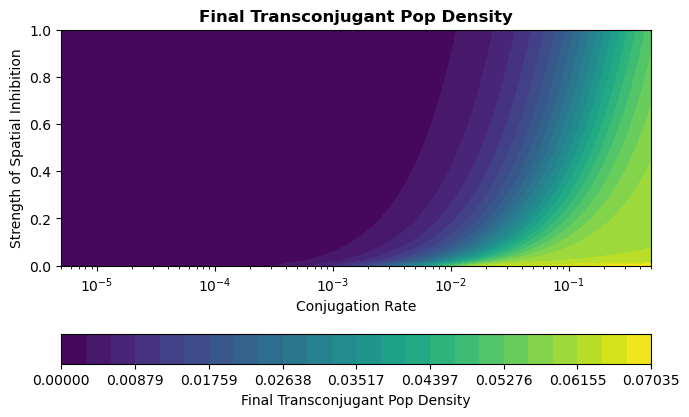

In [27]:
conjugation_rate = np.logspace(-6, -1, 101, base=10)*5
prop_strength = np.linspace(0, 1, 51)
final_transconjugants = np.load(f'{datadir}change_prop_strength.npy').mean(axis=2)

# Plot the results of the effect of susceptibility on transconjugants
fig, ax = plt.subplots(figsize=(7,5))
n_transconjugants = ax.contourf(conjugation_rate, prop_strength, final_transconjugants.T, cmap='viridis', levels=np.linspace(final_transconjugants.min(), final_transconjugants.max(), 25))
plt.colorbar(n_transconjugants, label='Final Transconjugant Pop Density', location='bottom', orientation='horizontal')
ax.set_aspect(aspect=2)
ax.set_xlabel('Conjugation Rate')
ax.set_xscale('log')
ax.set_ylabel('Strength of Spatial Inhibition')
plt.title('Final Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_prop_strength.png', dpi=500)
plt.show()

### Comparing Clonal Expansion and Plasmid Transfer Rates

The growth rates are recalculated *post-hoc* to determine the contribution of clonal expansion (general growth/decline rates) and conjugation (adding to the population via `plasmid_transfer`) using the `determine_species_growth_rates(*parameters)`. 

The change in the donor, recipient, and transconjugant population densities is calculated by subtracting the previous timepoint population density from the following one, and `0` is inserted at the start of each array. 

Then, the `plasmid_transfer` term is recalculated *a posteriori* from the outputted `results` array using the relevant method (`simple` or `proportion` depending on what was used in the simulation). This is done as it is hard to retrieve intermediate values from the `solve_ivp` function, and multiple calculations are made for each timepoint to determine the most accurate to use, therefore more values will be saved than correspond to the used timepoints. Once the values are calculated, the final calculated `plasmid_transfer` value is removed (as that would be for an extra timepoint `t_end + 1`), and `0` is inserted at the start.

This `plasmid_transfer` array is then added to the recipient results and removed from the transconjugant results, to determine recipient growth without losing the population to conjugation, and to identify solely clonal expansion, respectively.

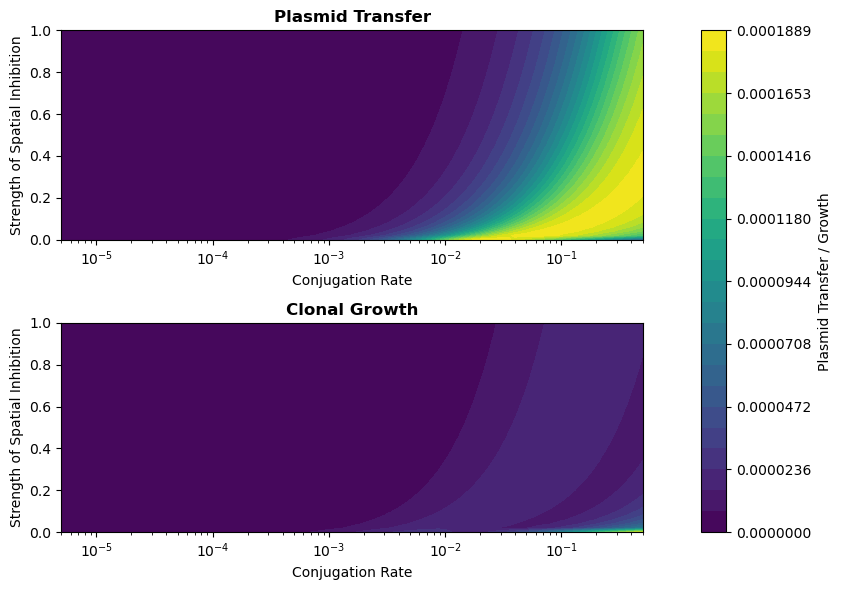

In [28]:
conjugation_rate = np.logspace(-6, -1, 101, base=10)*5
prop_strength = np.linspace(0, 1, 51)
mean_conjugation = np.load(f'{datadir}mean_conjugation.npy').mean(axis=2)
mean_clonal = np.load(f'{datadir}mean_clonal.npy').mean(axis=2)

# Plot the results of the effect of susceptibility on transconjugants
fig, ax = plt.subplots(2,1,figsize=(12,6))
levels = np.linspace(min(np.array([mean_conjugation, mean_clonal]).flatten()), max(np.array([mean_conjugation, mean_clonal]).flatten()), 25)

# Mean Conjugation
prop = ax[0].contourf(conjugation_rate, prop_strength, mean_conjugation.T, cmap='viridis', levels=levels)
ax[0].set_aspect(aspect=1.8)
ax[0].set_xlabel('Conjugation Rate')
ax[0].set_xscale('log')
ax[0].set_ylabel('Strength of Spatial Inhibition')
ax[0].set_title('Plasmid Transfer', fontweight='bold')

# Mean Conjugation
prop = ax[1].contourf(conjugation_rate, prop_strength, mean_clonal.T, cmap='viridis', levels=levels)
ax[1].set_aspect(aspect=1.8)
ax[1].set_xlabel('Conjugation Rate')
ax[1].set_xscale('log')
ax[1].set_ylabel('Strength of Spatial Inhibition')
ax[1].set_title('Clonal Growth', fontweight='bold')

plt.tight_layout()
fig.colorbar(prop, ax=ax.ravel().tolist(), label='Plasmid Transfer / Growth')
plt.savefig(f'{figdir}vary_prop_clonal_conjugation.png', dpi=500)
plt.show()

## Drug Perturbation

Now that a working model, that can incorporate plasmid transfer, has been created - we can introduce drug perturbation. 

The overall `drug_effect` is determined by the drug strength $p$ at time $t$, as well as the `susceptibility` $\epsilon$ of each species to the drug. The `drug_effect` term calculated is subtracted from each species' population density to model the reduced population growth of a species perturbed by a drug.

The effect of drug perturbation on the model is time-dependent, where the drug is introduced to the system at `t_drug` and removed at `drug_recovery`. The strength of the drug $p$ is then set as an array, `drug_time`. The array is set to `0` at `t < t_drug & t > t_drug_recovery` and set to `drug_level` at `t_drug < t < t_drug_recovery`.

At each timepoint `t`, `drug_time` is then indexed and multiplied by the `susceptibility` for each species.

### Changing Antibiotic Introduction/Removal

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.03759165]
 [-0.1        -0.1        -0.1        -0.03759165]
 [-0.1        -0.1        -0.1        -0.03759165]
 [-0.24709773 -0.24709773 -0.24709773 -0.1       ]]

The growth rate is:
[0.13760115 0.13759934 0.13759425 0.84133269]



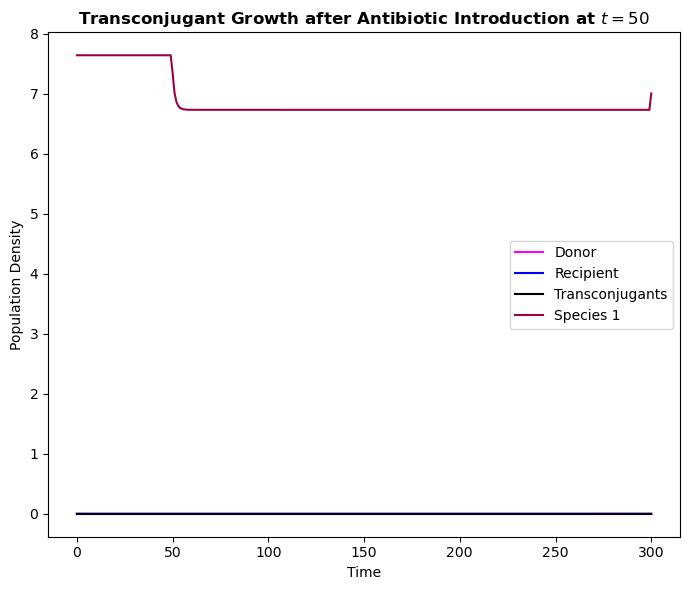

In [29]:
# PARAMETERS FOR CHANGING ANTIBIOTIC TIME
n_species = 1                              # number of different species in the community (in addition to donor and recipient)
# Parameters for the interaction matrix
connectivity = 1                           # community connectivty (probability of interactions)
sigma = 0.6                                # interspecies interaction strength standard deviation
P_m = 0                                    # proportion of species reactions that are positive
self_inhibition = 0.1                      # intra-specific interaction strength
intrinsic_growth = 1                       # instrinsic growth rate
# Parameters at the start of the model
t_start = 0                                # starting timestep
t_end = 300                                # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                    # starting population size
# Parameters for conjugation
conjugation_rate = 5e-4                    # average plasmid conjugation rate
# Parameters for the drug
susceptibility = [0.05, 0.05, 0.05, 0.2]     # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                           # magnitude of perturbation, between 0 and 1
t_drug = 50                                # time to introduce the drug
t_drug_recovery = t_end                    # time to allow recovery from drug

# INITIALISE MODEL
vary_anti_time = ode_lotka(n_species)  # initialise model
vary_anti_time.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
vary_anti_time.display_matrix_used()

# Run the model with only introducing antibiotic at certain time
vary_anti_time.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, t_drug=t_drug, t_drug_recovery=t_drug_recovery)  # solve ode
vary_anti_time.plot_results(vary_anti_time.results.t, vary_anti_time.results.y.T, f'Transconjugant Growth after Antibiotic Introduction at $t={t_drug}$')

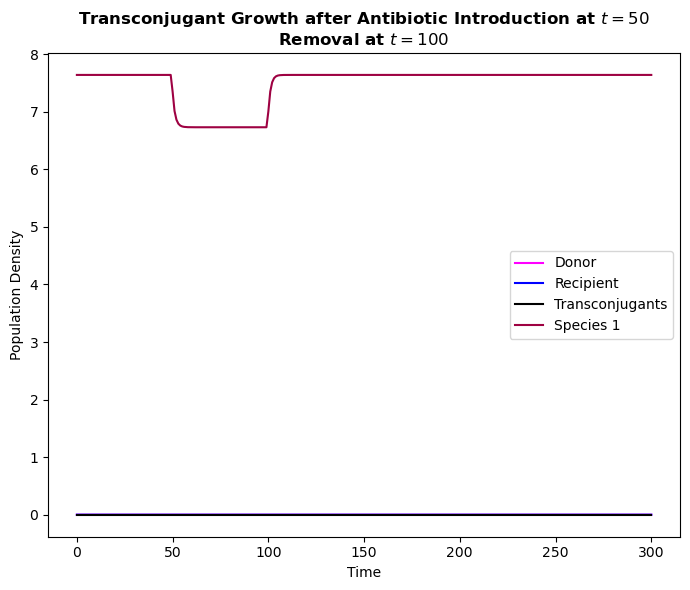

In [30]:
# PARAMETERS
t_drug_recovery = 100 # time to allow recovery from drug

# Run model
vary_anti_time.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, t_drug=t_drug, t_drug_recovery=t_drug_recovery)  # solve ode
vary_anti_time.plot_results(vary_anti_time.results.t, vary_anti_time.results.y.T, f'Transconjugant Growth after Antibiotic Introduction at $t={t_drug}$\nRemoval at $t={t_drug_recovery}$')

### Drug Strength

The drug strength $p$ is given as a proportion on a scale of $0$ to $1$ to be able to modulate the strength of the perturbation. In the graph below, when the community is much more susceptible to the drug than the donor, recipient, and transconjugant, the drug can perturb the surrounding community, allowing the donor and recipient to overgrow and conjugation to occur. However, too high a drug concentration can affect the donor and recipient's growth, even if the have very low susceptibilities to it.

In [31]:
# PARAMETERS

# Number of species to use
n_species = 1                                     # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                  # community connectivty (probability of interactions)
sigma = 0.6                                       # interspecies interaction strength standard deviation
P_m = 0                                           # proportion of species reactions that are positive
self_inhibition = 0.1                             # intra-specific interaction strength
intrinsic_growth = 1                              # instrinsic growth rate

# Parameters for the model
conjugation_rate = 5e-4                           # average plasmid conjugation rate
susceptibility = [0.05, 0.05, 0.05, 0.5]          # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = np.linspace(0, 1, 51)                # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                       # starting timestep
t_end = 300                                       # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                           # starting population size

In [32]:
# Initialise model
vary_drug_strength = ode_lotka(n_species)  # initialise model
repeat = 30

final_transconjugants = np.zeros([len(drug_level), repeat])  # array to save data in
for r in range(repeat):
    vary_drug_strength.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
    print(f'Repeat {r+1}')
    # Try different conjugation_rate values
    for s in range(len(drug_level)):  # loop through recipient susceptibilities
        vary_drug_strength.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level[s])  # solve ode
        final_transconjugants[s][r] = vary_drug_strength.results.y[2, -1]  # final number of transconjugants
np.save(f'{datadir}change_drug_strength', final_transconjugants)

Repeat 1
Repeat 2
Repeat 3
Repeat 4
Repeat 5
Repeat 6
Repeat 7
Repeat 8
Repeat 9
Repeat 10
Repeat 11
Repeat 12
Repeat 13
Repeat 14
Repeat 15
Repeat 16
Repeat 17
Repeat 18
Repeat 19
Repeat 20
Repeat 21
Repeat 22
Repeat 23
Repeat 24
Repeat 25
Repeat 26
Repeat 27
Repeat 28
Repeat 29
Repeat 30


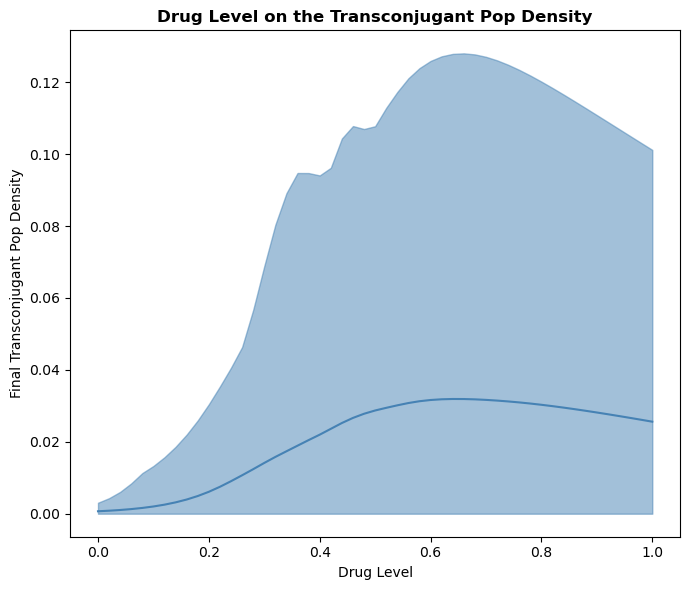

In [33]:
#Load data
drug_level = np.linspace(0, 1, 51)
final_transconjugants = np.load(f'{datadir}change_drug_strength.npy')
 
# Plot the results of the effect of conjugation_rate on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
plt.plot(drug_level, final_transconjugants.mean(axis=1), color='steelblue')
plt.fill_between(drug_level, np.percentile(final_transconjugants, 5, axis=1), np.percentile(final_transconjugants, 95, axis=1), alpha=0.5, color='steelblue')
ax.set_xlabel('Drug Level')
ax.set_ylabel('Final Transconjugant Pop Density')
plt.title('Drug Level on the Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{figdir}vary_drug_level_transconjugants.png', dpi=500)
plt.show()

### Varying Susceptibility on Transconjugants

Each species then can have varying susceptibilities $\epsilon$ to the drug provided, including the donor, recipient and transconjugant species. 

The code below identifies the effect of drug susceptibility on the donors, recipients and a single species community on conjugation. the Transconjugant species has the same susceptibility as recipient, unless the donor has a low susceptibility, in which case it takes the 'donated' antibiotic resistance gene which confers greater resistance.

In [34]:
# PARAMETERS

# Number of species to use
n_species = 1                                       # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                    # community connectivty (probability of interactions)
sigma = 0.6                                         # interspecies interaction strength standard deviation
P_m = 0                                             # proportion of species reactions that are positive
self_inhibition = 0.1                               # intra-specific interaction strength
intrinsic_growth = 1                                # instrinsic growth rate

# Parameters for the model
conjugation_rate = 5e-4                             # average plasmid conjugation rate
donor_sus = np.linspace(0, 1, 21)                   # VARYING: susceptibility of donor
recipient_sus = np.linspace(0, 1, 21)               # VARYING: susceptibility of recipient
community_sus = np.linspace(0, 1, 21)               # VARYING: susceptibility of community
drug_level = 0.5                                    # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                         # starting timestep
t_end = 300                                         # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                             # starting population size

In [35]:
# Initialise model
replicate_laura = ode_lotka(n_species)  # initialise model

# Try different community and antibiotic susceptibilities
repeat = 15
final_transconjugants = np.zeros([len(community_sus), len(recipient_sus), len(donor_sus), repeat])  # array to save data in
for r in range(repeat):
    print(f'Starting repeat {r+1}')
    replicate_laura.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
    for ds in range(len(donor_sus)):
        print(f'\tStarting donor susceptibility #{ds+1}')
        for rs in range(len(recipient_sus)):  # loop through recipient susceptibilities
            for cs in range(len(community_sus)):  # loop through community susceptibilities
                if (0 in [donor_sus[ds], recipient_sus[rs], community_sus[cs]]) or (1 in [donor_sus[ds], recipient_sus[rs], community_sus[cs]]):
                    susceptibility = np.array([donor_sus[ds], recipient_sus[rs], np.min([donor_sus[ds], recipient_sus[rs]]), community_sus[cs]])  # set current susceptibility list
                    replicate_laura.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode
                    final_transconjugants[cs][rs][ds][r] = replicate_laura.results.y[2, -1]  # final number of transconjugants
np.save(f'{datadir}change_susceptibility', final_transconjugants)

Starting repeat 1
	Starting donor susceptibility #1
	Starting donor susceptibility #2
	Starting donor susceptibility #3
	Starting donor susceptibility #4
	Starting donor susceptibility #5
	Starting donor susceptibility #6
	Starting donor susceptibility #7
	Starting donor susceptibility #8
	Starting donor susceptibility #9
	Starting donor susceptibility #10
	Starting donor susceptibility #11
	Starting donor susceptibility #12
	Starting donor susceptibility #13
	Starting donor susceptibility #14
	Starting donor susceptibility #15
	Starting donor susceptibility #16
	Starting donor susceptibility #17
	Starting donor susceptibility #18
	Starting donor susceptibility #19
	Starting donor susceptibility #20
	Starting donor susceptibility #21
Starting repeat 2
	Starting donor susceptibility #1
	Starting donor susceptibility #2
	Starting donor susceptibility #3
	Starting donor susceptibility #4
	Starting donor susceptibility #5
	Starting donor susceptibility #6
	Starting donor susceptibility #7


In [36]:
# Load transconjugant info
final_transconjugants = np.load(f'{datadir}change_susceptibility.npy')
final_transconjugants = final_transconjugants.mean(axis=3)

# Info for 4D plotting
X_donor, Y_recip, Z_comm = np.meshgrid(donor_sus, recipient_sus, community_sus)
kw = {'vmin': final_transconjugants.min(),
      'vmax': final_transconjugants.max(),
      'levels': np.linspace(final_transconjugants.min(), final_transconjugants.max(), 20),}

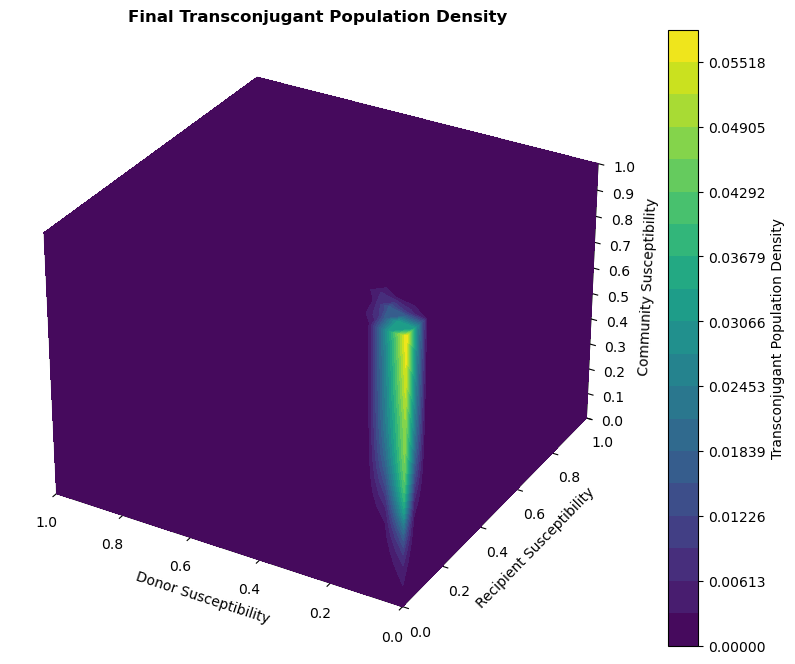

In [37]:
# Create the 3D contour plot with data on the axis
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
# Plot contour surfaces
_ = ax.contourf(X_donor[:, :, 0], Y_recip[:, :, 0], final_transconjugants[-1, :, :], zdir='z', offset=0, **kw, cmap='viridis')
_ = ax.contourf(X_donor[0, :, :], np.rot90(final_transconjugants[:, 0, :], axes=(1, 0)), Z_comm[0, :, :], zdir='y', offset=0, **kw, cmap='viridis')
C = ax.contourf(np.rot90(final_transconjugants[:, :, 0], axes=(1, 0)), Y_recip[:, 0, :], Z_comm[0, :, :], zdir='x', offset=0, **kw, cmap='viridis')
# Se lims and title
ax.set(xlabel='Donor Susceptibility',
       xlim=[X_donor.max(), X_donor.min()],
       ylabel='Recipient Susceptibility',
       ylim=[Y_recip.min(), Y_recip.max()],
       zlabel='Community Susceptibility',
       zlim=[Z_comm.max(), Z_comm.min()])
ax.set_zticks(np.linspace(0, 1, 11), labels=[f'{label:.1f}' for label in np.flip(community_sus[0::2].tolist())])
plt.title('Final Transconjugant Population Density', fontweight='bold')
# Set colourbar
divider = make_axes_locatable(ax)
cax = divider.append_axes('right', size='10%', pad=0.95)
cax.grid(False)
cax.axis('off')
fig.colorbar(C, ax=cax, label='Transconjugant Population Density')
plt.savefig(f'{figdir}vary_susceptibility.png', dpi=500)
plt.show()

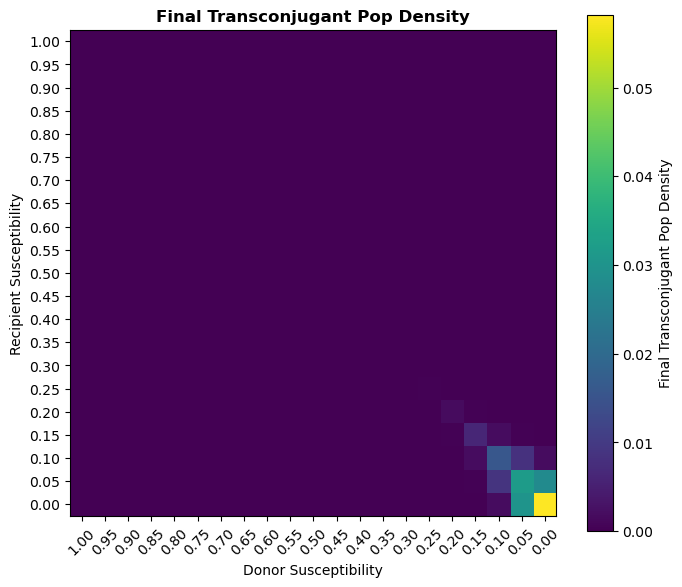

In [38]:
# Plot the results of the effect of susceptibility on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
n_transconjugants = ax.imshow(final_transconjugants[-1,:,:], cmap='viridis')
plt.colorbar(n_transconjugants, label='Final Transconjugant Pop Density')
ax.set_xlabel('Donor Susceptibility')
ax.set_xlim(20.5, -0.5)
ax.set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax.set_ylabel('Recipient Susceptibility')
ax.set_ylim(-0.5,20.5)
ax.set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recipient_sus.tolist()])
plt.title('Final Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.show()

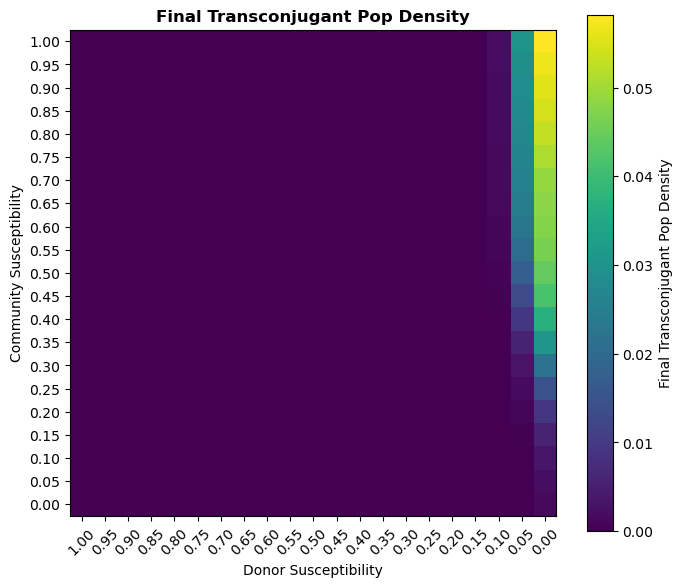

In [39]:
# Plot the results of the effect of susceptibility on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
n_transconjugants = ax.imshow(final_transconjugants[:,0,:], cmap='viridis')
plt.colorbar(n_transconjugants, label='Final Transconjugant Pop Density')
ax.set_xlabel('Donor Susceptibility')
ax.set_xlim(20.5,-0.5)
ax.set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in donor_sus.tolist()], rotation=45)
ax.set_ylabel('Community Susceptibility')
ax.set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in community_sus.tolist()])
ax.set_ylim(-0.5, 20.5)
plt.title('Final Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.show()

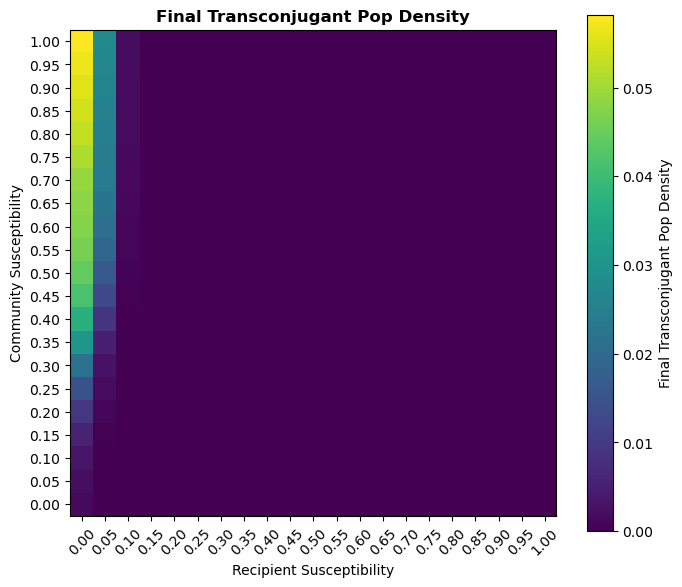

In [40]:
# Plot the results of the effect of susceptibility on transconjugants
fig, ax = plt.subplots(figsize=(7,6))
n_transconjugants = ax.imshow(final_transconjugants[:,:,0], cmap='viridis')
plt.colorbar(n_transconjugants, label='Final Transconjugant Pop Density')
ax.set_xlabel('Recipient Susceptibility')
ax.set_xticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in recipient_sus.tolist()], rotation=45)
ax.set_ylabel('Community Susceptibility')
ax.set_yticks(np.linspace(0, 20, 21), labels=[f'{label:.2f}' for label in community_sus.tolist()])
ax.set_ylim(-0.5, 20.5)
plt.title('Final Transconjugant Pop Density', fontweight='bold')
plt.tight_layout()
plt.show()

## Combining Susceptibility and Conjugation

**How much of the transconjugant growth is from conjugation, and how much is from one lucky event, and the rest from clonal expansion?**
Once conjugation occurs, the pool of potential donors increases (the now transconjugants), which have the susceptibility of the recipient. However, conjugation rates should still hypothetically be quite low, so how much conjugation actually occurs vs growth?

In [41]:
# PARAMETERS

# Number of species to use
n_species = 1                                   # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                # community connectivty (probability of interactions)
sigma = 0.6                                     # interspecies interaction strength standard deviation
P_m = 0                                         # proportion of species reactions that are positive
self_inhibition = 0.1                           # intra-specific interaction strength
intrinsic_growth = 1                            # instrinsic growth rate

# Parameters to run the model
t_start = 0                                     # starting timestep
t_end = 300                                     # ending timestep

# Parameters for conjugation
conjugation_rate = 5e-4                         # average plasmid conjugation rate

# Parameters for the drug
drug_level = 0.7                                # magnitude of perturbation, between 0 and 1

# Direct selection
x0 = [5e-5, 5e-5, 0, 1]                         # starting population size
susceptibility = [0.9, 0.5, 0.5, 0.9]           # susceptibility of susceptible taxa (vector to allow for variability between taxa)

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.03214503]
 [-0.1        -0.1        -0.1        -0.03214503]
 [-0.1        -0.1        -0.1        -0.03214503]
 [-0.082638   -0.082638   -0.082638   -0.1       ]]

The growth rate is:
[0.13215215 0.1321434  0.13215365 0.34792644]



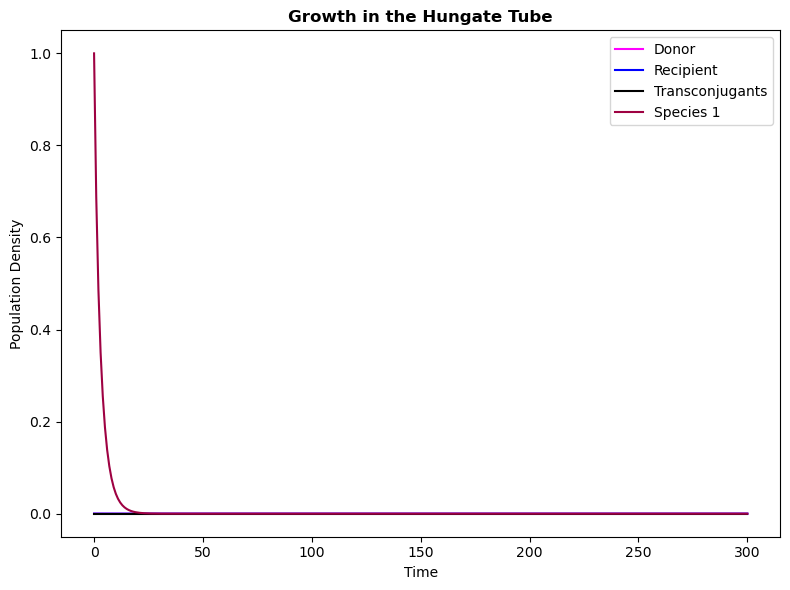

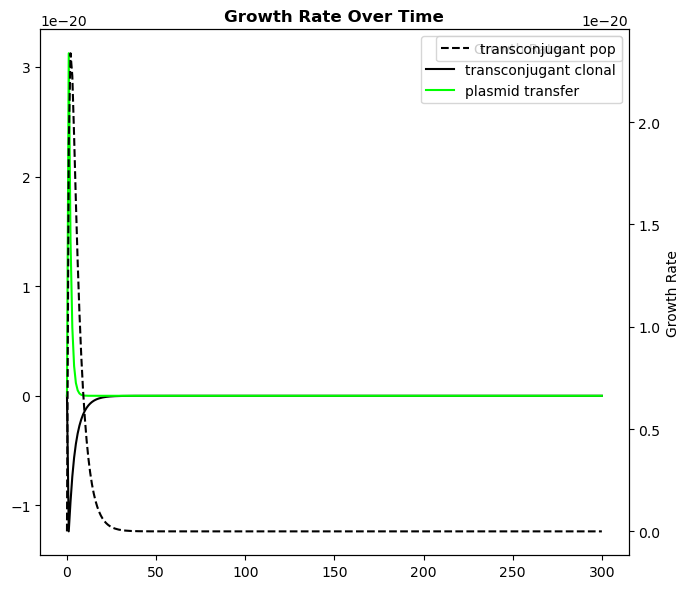

In [42]:
# Initialise model
direct_selection = ode_lotka(n_species)  # initialise model
direct_selection.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
direct_selection.display_matrix_used()
# Run model and plot the equilibrium and the general growth with simple conjugation that doesn't take into account population
direct_selection.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, equilibrium=False)  # solve ode
direct_selection.plot_results(direct_selection.results.t, direct_selection.results.y.T, 'Growth in the Hungate Tube', figsize=(8,6))
direct_selection.plot_growth_rates(conjugation_rate)

## Running the Model

Once the parameters of the model have been set up, and the interaction matrix and growth rates have been calculated, the system of ODEs can be solved. The `scipy` function `solve_ivp()` is used from `t_start < t < t_end` to solve the system of equations:

$$ 
\begin{bmatrix} dDdt \\ dRdt \\ dTdt \\ dC_1dt \\ ... \end{bmatrix} = 
\begin{bmatrix} dX_Ddt\\ dX_Rdt \\ dX_Tdt \\ dX_{C_1}dt \\ ... \end{bmatrix} - 
\begin{bmatrix} X_Dm_D \\ X_Rm_R \\ X_Tm_T \\ X_{C_1}m_{C_1} \\ ... \end{bmatrix} -
\begin{bmatrix} X_D\epsilon_Dp(t) \\ X_R\epsilon_Rp(t) \\ X_T\epsilon_Tp(t) \\ X_{C_1}\epsilon_{C_1}p(t) \\ ... \end{bmatrix} + 
\begin{bmatrix} 0 \\ - \gamma \\ \gamma \\ 0 \\ ... \end{bmatrix}
$$
where $\mathbf{dXdt} = \mathbf{X} [r + (\mathbf{\alpha} \times \mathbf{X})]$ and $\mathbf{m} = 0.001 + 0.01\mathbf{X}$

`solve_ivp` outputs the array of every timestep a calculation was done, as well as `(t_end + 1) x n_species` array with the population density for each species at each timepoint. This can be used for further analysis and graphing to view the outputs. 

### Simple 1 Species Model
This is a test run of the model to ensure it works with the singular community species, and how it affects the growth of the donor, recipient and transconjugants.

In [43]:
# PARAMETERS

# Number of species to use
n_species = 1                                                        # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                                     # community connectivty (probability of interactions)
sigma = 0.6                                                          # interspecies interaction strength standard deviation
P_m = 0                                                              # proportion of species reactions that are positive
self_inhibition = 0.1                                                # intra-specific interaction strength
intrinsic_growth = 1                                                 # instrinsic growth rate

# Parameters for the model
conjugation_rate = 5e-4                                              # average plasmid conjugation rate
susceptibility = [0.05, 0.05, 0.05, 0.5]                             # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                                                     # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                                          # starting timestep
t_end = 300                                                          # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                              # starting population size

In [44]:
# Run model
one_species_community = ode_lotka(n_species)  # initialise model
one_species_community.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
one_species_community.display_matrix_used()
one_species_community.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.00982511]
 [-0.1        -0.1        -0.1        -0.00982511]
 [-0.1        -0.1        -0.1        -0.00982511]
 [-0.14549651 -0.14549651 -0.14549651 -0.1       ]]

The growth rate is:
[0.10983102 0.10983341 0.10983106 0.53652396]



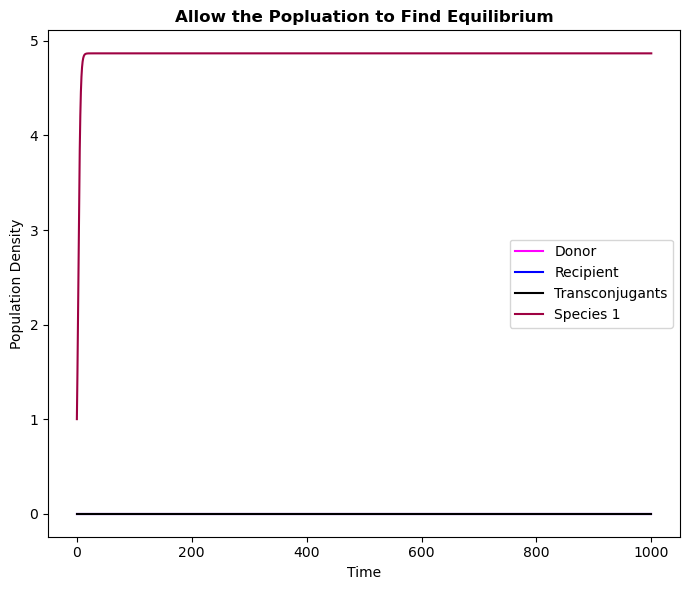

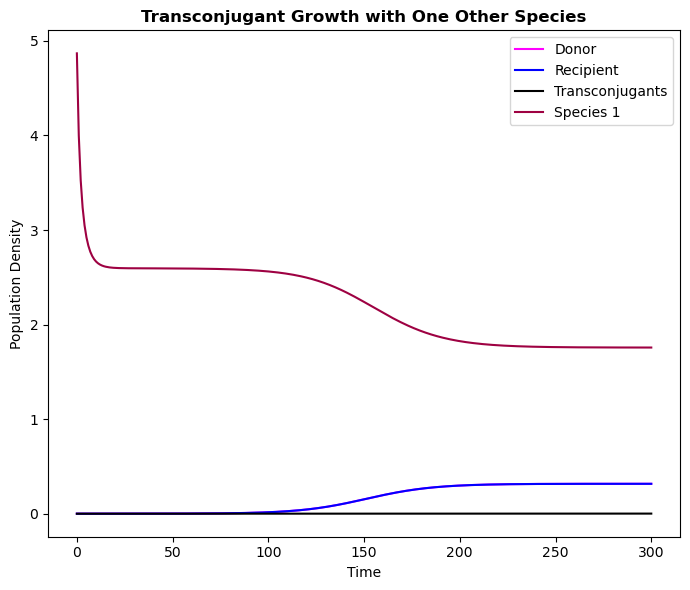

In [45]:
# Plot the equilibrium and the general growth
one_species_community.plot_results(one_species_community.equilibrium.t, one_species_community.equilibrium.y.T, 'Allow the Popluation to Find Equilibrium')
one_species_community.plot_results(one_species_community.results.t, one_species_community.results.y.T, 'Transconjugant Growth with One Other Species')

### Complex 1 Species Model

These cells are now attempting to model something close to the Hungate tube experiments. The community is not allowed to find equilibrium (mimicking taking the community directly from glycerol stock) and placed directly with the drug. 

After growing for a length of time (meant to be equivalent to 24hrs), the donor and the recipient are added. They are left for a time equivalent to 5hrs (5/24) before the drug is removed from the community, allowing potential recovering.

Conjugation occurs not just taking into account the strength of the interactions between species and how it inhibits or allows growth of the donor and recipient, but also how the other species in the community may spatially inhibit the donor and recipient coming into contact with each other to allow conjugation to occur.

In [46]:
# PARAMETERS

# Number of species to use
n_species = 1                                                        # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                                     # community connectivty (probability of interactions)
sigma = 0.6                                                          # interspecies interaction strength standard deviation
P_m = 0                                                              # proportion of species reactions that are positive
self_inhibition = 0.1                                                # intra-specific interaction strength
intrinsic_growth = 1                                                 # instrinsic growth rate

# Parameters to run the model
t_start = 0                                                          # starting timestep
t_end = 300                                                          # ending timestep
x0 = [5e-5, 5e-5, 0, 1]                                              # starting population size

# Parameters for conjugation
t_dr = 60                                                           # time that the donor and recipient are
prop_strength = 0.2                                                  # how strongly the spatial inhibition should be considered (from 0, not at all, to 1)
conjugation_rate = 5e-4                                              # average plasmid conjugation rate

# Parameters for the drug
susceptibility = [0.05, 0.05, 0.05, 0.5]                             # susceptibility of susceptible taxa (vector to allow for variability between taxa)
drug_level = 0.5                                                     # magnitude of perturbation, between 0 and 1
t_drug = 0                                                           # time to introduce the drug
t_drug_recovery = 95                                                 # time to allow recovery from drug

In [47]:
# Initialise model
hungate_species1 = ode_lotka(n_species)  # initialise model
hungate_species1.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
hungate_species1.display_matrix_used()
# Run model and plot the equilibrium and the general growth with simple conjugation that doesn't take into account population
hungate_species1.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, equilibrium=False, plasmid_method='proportion', prop_strength=prop_strength, t_dr=t_dr, t_drug=t_drug, t_drug_recovery=t_drug_recovery)  # solve ode
#hungate_species1.plot_results(hungate_species1.results.t, hungate_species1.results.y.T, 'Growth in the Hungate Tube', figsize=(8,6), save_fig=True)

The interaction matrix used for this run is:
[[-1.00000000e-01 -1.00000000e-01 -1.00000000e-01 -1.86098242e-04]
 [-1.00000000e-01 -1.00000000e-01 -1.00000000e-01 -1.86098242e-04]
 [-1.00000000e-01 -1.00000000e-01 -1.00000000e-01 -1.86098242e-04]
 [-4.12356470e-01 -4.12356470e-01 -4.12356470e-01 -1.00000000e-01]]

The growth rate is:
[0.10018657 0.10019793 0.10018861 1.33713818]



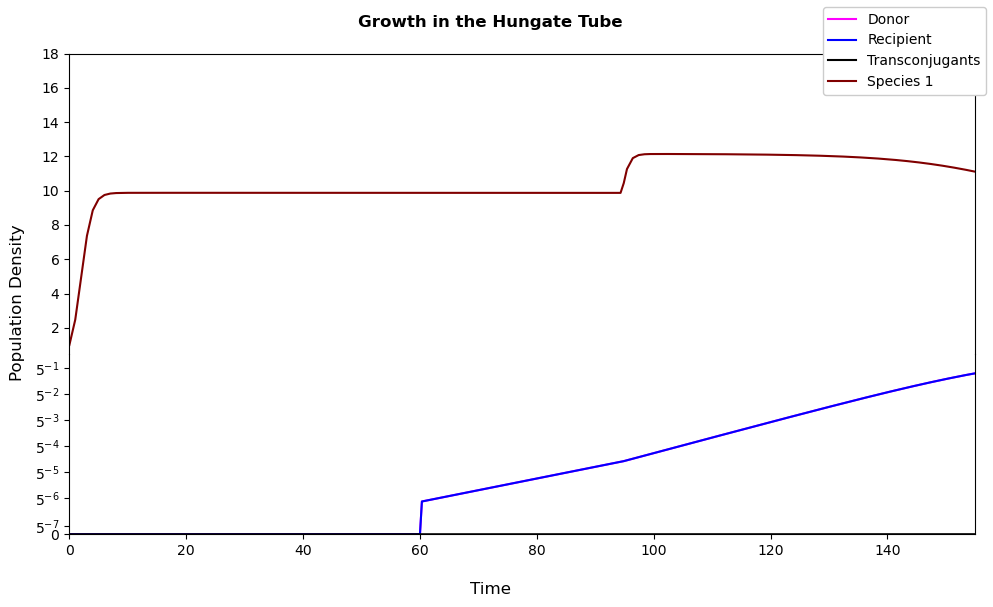

In [48]:
fig, axLog = plt.subplots(figsize=(10,6))
colours = ['magenta', 'b', 'black', 'maroon']
labels = ['Donor', 'Recipient', 'Transconjugants', 'Species 1']

for i, (c, l) in enumerate(zip(colours, labels)):
    axLog.plot(hungate_species1.results.t, hungate_species1.results.y[i], color=c, label=l)
axLog.set_yscale('symlog', base=5, linthresh=5e-5)
axLog.set_ylim((0, 0.5))
axLog.spines['top'].set_visible(False)
axLog.xaxis.set_ticks_position('bottom')

divider = make_axes_locatable(axLog)
axLin = divider.append_axes("top", size=3, pad=0, sharex=axLog)
for i, (c, l) in enumerate(zip(colours, labels)):
    axLin.plot(hungate_species1.results.t,hungate_species1.results.y[i], color=c)
axLin.set_xscale('linear')
axLin.set_ylim((0.5, 18))
axLin.spines['bottom'].set_visible(False)
axLin.xaxis.set_ticks_position('none')
plt.setp(axLin.get_xticklabels(), visible=False)

fig.legend(framealpha=1)
plt.xlim(0,155)
fig.supxlabel('Time')
fig.supylabel('Population Density')
fig.suptitle('Growth in the Hungate Tube', fontweight='bold')
plt.tight_layout()
#plt.savefig('microbiota_density.png', dpi=500)

### Simple MM12 Species Model
This is a run of the model in an 'MM12' community, to mimic some of the mouse communities

In [49]:
# PARAMETERS

# Number of species to use
n_species = 12                                                       # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 1                                                     # community connectivty (probability of interactions)
sigma = 0.05                                                         # interspecies interaction strength standard deviation
P_m = 0                                                              # proportion of species reactions that are positive
self_inhibition = 0.1                                                # intra-specific interaction strength
intrinsic_growth = 1                                                 # instrinsic growth rate

# Parameters for the model
conjugation_rate = 5e-4                                              # average plasmid conjugation rate
susceptibility = [0.05, 0.05, 0.05, 0.3, 0.2, 0.15, 0.24, 0.18, 0.3, 0.5, 0.45, 0.6, 0.57, 0.4, 0.45]
drug_level = 0.5                                                     # magnitude of perturbation, between 0 and 1

# Parameters at the start of the model
t_start = 0                                                          # starting timestep
t_end = 300                                                          # ending timestep
x0 = [5e-5, 5e-5, 0, 1.5, 1.2, 1.3, 0.8, 1, 0.75, 0.9, 1, 0.5, 1, 1.12, 1.62]

In [50]:
# Run model
mm12_community = ode_lotka(n_species)  # initialise model
mm12_community.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
mm12_community.display_matrix_used()
mm12_community.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level)  # solve ode

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.07051647 -0.02067234 -0.02972676
  -0.00438368 -0.02200124 -0.03353433 -0.08983007 -0.06823795 -0.00424135
  -0.01970879 -0.03437669 -0.0631208 ]
 [-0.1        -0.1        -0.1        -0.07051647 -0.02067234 -0.02972676
  -0.00438368 -0.02200124 -0.03353433 -0.08983007 -0.06823795 -0.00424135
  -0.01970879 -0.03437669 -0.0631208 ]
 [-0.1        -0.1        -0.1        -0.07051647 -0.02067234 -0.02972676
  -0.00438368 -0.02200124 -0.03353433 -0.08983007 -0.06823795 -0.00424135
  -0.01970879 -0.03437669 -0.0631208 ]
 [-0.02720171 -0.02720171 -0.02720171 -0.1        -0.04646682 -0.00051158
  -0.03392377 -0.06387233 -0.03386551 -0.03582187 -0.05877098 -0.01779881
  -0.01930791 -0.08497259 -0.05432058]
 [-0.06027258 -0.06027258 -0.06027258 -0.00366355 -0.1        -0.03633626
  -0.01900766 -0.03135559 -0.0443169  -0.0542114  -0.02413039 -0.00921791
  -0.09950088 -0.00532784 -0.00736738]
 [-0.02831913 -0.028

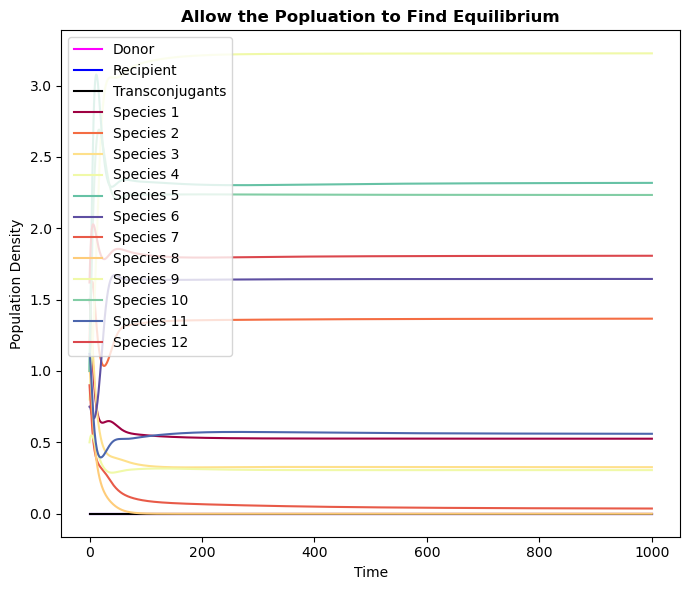

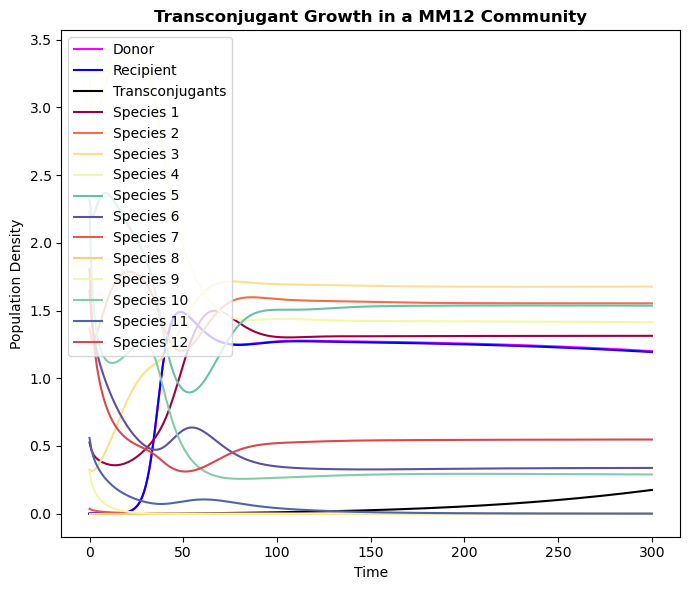

In [51]:
# Plot the equilibrium and the general growth
mm12_community.plot_results(mm12_community.equilibrium.t, mm12_community.equilibrium.y.T, 'Allow the Popluation to Find Equilibrium')
mm12_community.plot_results(mm12_community.results.t, mm12_community.results.y.T, 'Transconjugant Growth in a MM12 Community')

### Complex MM12 Species Model

These cells are now attempting to model something close to the Hungate tube experiments. The community is not allowed to find equilibrium (mimicking taking the community directly from glycerol stock) and placed directly with the drug. 

After growing for a length of time (meant to be equivalent to 24hrs), the donor and the recipient are added. They are left for a time equivalent to 5hrs (5/24) before the drug is removed from the community, allowing potential recovering.

Conjugation occurs not just taking into account the strength of the interactions between species and how it inhibits or allows growth of the donor and recipient, but also how the other species in the community may spatially inhibit the donor and recipient coming into contact with each other to allow conjugation to occur.

In [52]:
# PARAMETERS

# Number of species to use
n_species = 12                                                        # number of different species in the community (in addition to donor and recipient)

# Parameters for the interaction matrix
connectivity = 0.9                                                   # community connectivty (probability of interactions)
sigma = 0.05                                                         # interspecies interaction strength standard deviation
P_m = 0.1                                                            # proportion of species reactions that are positive
self_inhibition = 0.1                                                # intra-specific interaction strength
intrinsic_growth = 1                                                 # instrinsic growth rate

# Parameters to run the model
t_start = 0                                                          # starting timestep
t_end = 300                                                          # ending timestep
x0 = [5e-5, 5e-5, 0, 1.5, 1.2, 1.3, 0.8, 1, 0.75, 0.9, 1, 0.5, 1, 1.12, 1.62]

# Parameters for conjugation
t_dr = 60                                                            # time that the donor and recipient are
prop_strength = 0.2                                                  # how strongly the spatial inhibition should be considered (from 0, not at all, to 1)
conjugation_rate = 5e-4                                              # average plasmid conjugation rate

# Parameters for the drug
susceptibility = [0.05, 0.05, 0.05, 0.3, 0.2, 0.15, 0.24, 0.18, 0.3, 0.5, 0.45, 0.6, 0.57, 0.4, 0.45]
drug_level = 0.5                                                     # magnitude of perturbation, between 0 and 1
t_drug = 0                                                           # time to introduce the drug
t_drug_recovery = 95                                                 # time to allow recovery from drug

The interaction matrix used for this run is:
[[-0.1        -0.1        -0.1        -0.04066654 -0.04457986 -0.05678593
  -0.05127377 -0.03092334 -0.0251254  -0.03282662 -0.02966462 -0.
  -0.09505709 -0.         -0.00066473]
 [-0.1        -0.1        -0.1        -0.04066654 -0.04457986 -0.05678593
  -0.05127377 -0.03092334 -0.0251254  -0.03282662 -0.02966462 -0.
  -0.09505709 -0.         -0.00066473]
 [-0.1        -0.1        -0.1        -0.04066654 -0.04457986 -0.05678593
  -0.05127377 -0.03092334 -0.0251254  -0.03282662 -0.02966462 -0.
  -0.09505709 -0.         -0.00066473]
 [-0.08015231 -0.08015231 -0.08015231 -0.1         0.03104895 -0.02151244
  -0.0222478  -0.08317604 -0.0263646   0.00180752 -0.         -0.
  -0.01180135 -0.02796391  0.03284118]
 [-0.05051456 -0.05051456 -0.05051456 -0.02467842 -0.1         0.02301453
  -0.01195123 -0.06115391 -0.10312198 -0.00224987 -0.0818628   0.0244571
  -0.03465103 -0.00986032 -0.        ]
 [-0.01517965 -0.01517965 -0.01517965 -0.         -0.

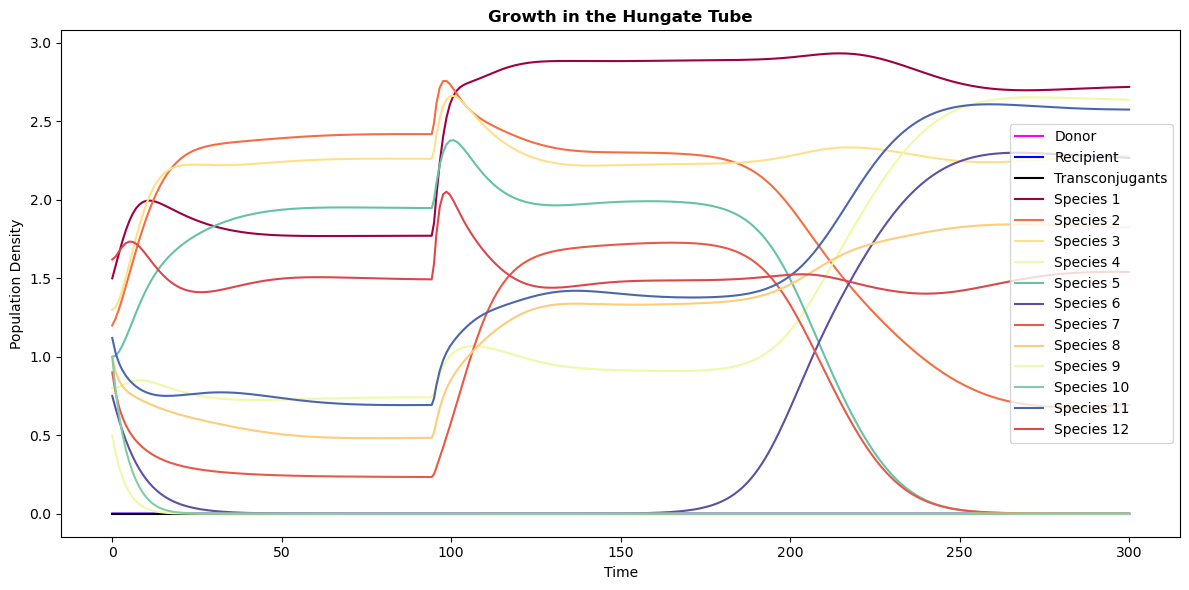

In [53]:
# Initialise model
hungate_species12 = ode_lotka(n_species)  # initialise model
hungate_species12.randomise_interaction_matrix(connectivity, sigma, P_m, self_inhibition, intrinsic_growth=intrinsic_growth)  # initialise interaction matrix
hungate_species12.display_matrix_used()
# Run model and plot the equilibrium and the general growth with simple conjugation that doesn't take into account population
hungate_species12.solve_ode(t_start, t_end, x0, conjugation_rate, susceptibility, drug_level, equilibrium=False, plasmid_method='proportion', prop_strength=prop_strength, t_dr=t_dr, t_drug=t_drug, t_drug_recovery=t_drug_recovery)  # solve ode
hungate_species12.plot_results(hungate_species12.results.t, hungate_species12.results.y.T, 'Growth in the Hungate Tube', figsize=(12,6))